# Neural networks for the Bitcoin forecasts

**Do neural networks forecast Bitcoin better than the classical models of `classical-models.ipynb`?** Every network runs on the same data, features, train / validation / test blocks and metrics, and is compared with a classical model refitted here on the same test days.

## Main results

| Question | Network chosen on validation | Test | Classical reference (refitted here) | Verdict |
|---|---|---|---|---|
| 24 hourly returns (the assigned task) | LSTM, Huber loss | MAE skill −0.0006 | Ridge −0.0003 | nothing beats predicting 0% |
| Direction of the next hour | LSTM classifier, every origin | AUC 0.538, top 10% right 59.9% | Gradient Boosting AUC 0.533 | tie |
| Size of each of the next 24 hours (\|r\|) | LSTM + hour features + volume attention, fine-tuned every month | R² **0.156** | Gradient Boosting refitted every month 0.148 | **network better (+0.008, reliable)** |
| Next-day volatility | ensemble GB + MLP | R² 0.516 | Gradient Boosting 0.505 | **ensemble better (+0.011, reliable)**; the MLP alone ties |

**In short:** for the size of the hourly moves, a network chosen without the test beats the best classical model for the first time in the project: an LSTM that knows the hours it predicts, reads the week through an attention mask of the traded volume and is fine-tuned every month. The margin is small (+0.008 R²). Where there is no signal (returns) the networks find none. For direction they tie Gradient Boosting, and for volatility they help as the second member of an ensemble.

## How to read this notebook

Sections 1–2 build the data and the tools. Sections 3–6 each answer one question (**question → models → code → "What we see"**, whose first line is the answer), section 7 tests which differences are reliable and section 8 sums up.

| Section | Question | Networks |
|---|---|---|
| 3 | 24 hourly returns | MLP, LSTM |
| 4 | Direction of the next hour | LSTM classifier |
| 5 | Size of each of the next 24 hours (**main experiment**) | MLP and LSTM variants, monthly refits, ensembles with GB |
| 6 | Next-day volatility | MLP, ensemble with GB |
| 7 | Bootstrap confidence intervals | — |
| 8 | Conclusions | — |

## Key terms

| Term | Meaning |
|---|---|
| **forecast origin** | the hour a forecast is made: every hour with 30 days of history before it and 24 hours after it |
| **every 6th origin / every origin** | train and validation keep one origin in six, as in the classical notebook; "every origin" uses all of them (6× more rows, but overlapping) |
| **wide / long format** | one row per origin / one row per origin and predicted hour (section 1.3) |
| **MAE skill, R²_oos** | 1 − MAE / MAE of the zero forecast, and R² against the zero forecast: above 0 beats predicting 0% |
| **IC** | correlation between forecasts and outcomes |
| **AUC** | quality of a direction forecast: 0.5 is a coin flip |
| **monthly refit / fine-tuning** | refit at the start of every month on everything known, recent months weighted more (5.1); for the LSTM, a few more epochs on the network of the month before (5.4b) |
| **scale-free target** | \|r\| divided by last week's average \|r\|, the forecast multiplied back (5.2) |
| **ensemble** | the plain average of several models' forecasts |
| **seeds** | every final network is trained `N_SEEDS` = 5 times; tables show the average forecast and the spread of single seeds |
| **reliable** | the 95% bootstrap interval of a difference excludes 0 (section 7) |

## Rules

As in `classical-models.ipynb`: blocks are cut by the date of the predicted hours with a 192-hour purge; every choice is made on train and validation; the test block is used **once**. Networks early-stop on the **last 6 months of train**, are scored on validation by a refit on the whole train block (section 2) and are refitted on train + validation for the final test forecast. The classical references are refitted here so that differences can be tested on the same days.

## Sources and scope

The networks come from `model_test.ipynb` (Adrián P.: LSTM in PyTorch on the 168-hour sequence) and versions 1–2 with their early draft (Alberto: scikit-learn `MLPRegressor`). The notebook covers README tasks 6–7 (window-normalized inputs, Huber loss, the targets with signal), 16 (fair validation, monthly refits of the LSTM) and 17 (release hours). It leaves out targets where the classical models found nothing to improve on (next-day return and direction, 80% ranges, economic test) and experiments that only repeated a known result: the RNN (always behind the LSTM), the Keras MLP of `course-methods.ipynb` (R² 0.40 against 0.51 for Linear Regression, `classical-models.ipynb` §9) and the choice of the monthly-refit variant (`classical-models.ipynb` §6.5). Data: `data/btc_hourly.csv.gz`, 1 Jan 2020 → 8 Oct 2026.

**Run time:** 33 minutes on a CUDA GPU (RTX 5060 Laptop). About half is the monthly refits of Gradient Boosting on the CPU (section 5.1, 15 minutes).

## 1. Settings, data, features and blocks

*Setup: to see the results, skip to section 3.*

Run from the repo root. Features, targets, metrics and tests come from `utils/hourly.py`; sections 1.1–1.3 repeat those of `classical-models.ipynb`, so origins and blocks are identical. Section 1.4 builds the input of the LSTM.

In [1]:
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"   # conda's MKL numpy and pip's torch each ship libiomp5md.dll (model_test.ipynb)
import sys
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from scipy import stats

from sklearn.base import clone
from sklearn.ensemble import HistGradientBoostingClassifier, HistGradientBoostingRegressor
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import Ridge
from sklearn.metrics import (balanced_accuracy_score, mean_absolute_error, mean_squared_error, r2_score,
                             roc_auc_score)
from sklearn.model_selection import GridSearchCV, ParameterGrid, TimeSeriesSplit
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

sys.path.insert(0, os.getcwd())   # utils/ is in the repo root
from utils import hourly as U
from utils.config import DATA_START, TEST_START, VAL_START
from utils.features import (NEXT_DAY_FEATURES, ORIGIN_FEATURES, TARGET_HOUR_FEATURES, load_releases,
                            next_day_release_features, origin_features, recent_hour_profile, target_hour_features)

warnings.filterwarnings("ignore", category=ConvergenceWarning)

DATA_PATH = os.path.join("data", "btc_hourly.csv.gz")
WINDOW = pd.Timedelta(hours=192)            # purge before each border (168 input + 24 target hours, versions 2-3)
STRIDE = 6                                  # train and validation keep every 6th forecast origin
SEQ_HOURS = 168                             # input length of the recurrent models (one week, as in model_test.ipynb)
N_SEEDS = 5                                 # every final network is trained with this many seeds
ES_MONTHS = 6                               # early stopping of the networks: the last 6 months of the train block
N_JOBS = 4                                  # parallel grid searches (section 6): each worker process reserves ~1 GB
RANDOM_STATE = 42
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
T_START = time.time()
np.random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)
print(f"PyTorch {torch.__version__}, device: {DEVICE}" + (f" ({torch.cuda.get_device_name(0)})" if DEVICE.type == "cuda" else ""))

# Colours and axes style shared by the plots (as in classical-models.ipynb)
BLUE, ORANGE, AQUA, GREY, INK, PURPLE = "#2a78d6", "#eb6834", "#1baf7a", "#b4b2a9", "#52514e", "#6250d6"


def tidy(ax, title=None):
    if title:
        ax.set_title(title, loc="left", fontsize=11)
    ax.grid(axis="y", color="#e5e4df", linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)

PyTorch 2.14.1+cu130, device: cuda (NVIDIA GeForce RTX 5060 Laptop GPU)


### 1.1 Data, forecast origins and targets

- Hourly data from 1 January 2020 (`DATA_START`); `Return` in **percent**. Older hours describe a different daily rhythm (`data-analysis.ipynb`).
- `y_all[i, h]` is the return of hour *h* + 1 after origin *i*.
- Inputs: the 42 scale-free **base** features of versions 1–2. The 30-day and range features of version 3 are computed only to align the first origin.
- From `utils/features.py`: **B4**, the last day at the origin (`rv_ratio_1d_30d`, `jump_ratio_1d`, `filled_minutes_1d`), and the releases of the next 24 hours (`next_day_*`, section 6). The features of the predicted hour are in section 1.3.

In [2]:
hourly = pd.read_csv(DATA_PATH, index_col="Timestamp", parse_dates=True).loc[DATA_START:].copy()
hourly["Return"] *= U.PCT
assert (hourly.index.to_series().diff().dropna() == pd.Timedelta(hours=1)).all(), "the hourly grid has holes"
ret, absr = hourly["Return"].values, hourly["Return"].abs().values

F_base, F_b1, F_b2 = U.base_features(hourly), U.long_lookback_features(hourly), U.range_vol_features(hourly)
FEAT = pd.concat([F_base, F_b1, F_b2], axis=1)
BASE = list(F_base.columns)

# forecast origins: every hour with all features defined (30 days of history) and 24 hours after it
ok = np.isfinite(FEAT.values).all(axis=1)
first = int(np.argmax(ok))
assert ok[first:].all(), "missing feature values inside the series"
pos_all = np.arange(first, len(hourly) - U.H_AHEAD)
origins = hourly.index[pos_all]
y_all = np.stack([ret[pos_all + k] for k in range(1, U.H_AHEAD + 1)], axis=1)     # next 24 returns, %

# features of data-analysis.ipynb, section 9.2 (utils/features.py), known at the origin: B4 and the releases of the next 24 h
releases = load_releases()
B4, B5 = list(ORIGIN_FEATURES), list(TARGET_HOUR_FEATURES)
FEAT = FEAT.join(origin_features(hourly)).join(next_day_release_features(hourly, releases))
assert np.isfinite(FEAT[B4 + NEXT_DAY_FEATURES].values[pos_all]).all()

print(f"{len(hourly):,} hours   {hourly.index[0]} -> {hourly.index[-1]}")
print(f"{len(origins):,} forecast origins   {origins[0]} -> {origins[-1]}")
print(f"base features: {len(BASE)}, B4 (origin): {len(B4)}, B5 (predicted hour): {len(B5)}")

59,331 hours   2020-01-01 00:00:00 -> 2026-10-08 02:00:00
58,588 forecast origins   2020-01-30 23:00:00 -> 2026-10-07 02:00:00
base features: 42, B4 (origin): 3, B5 (predicted hour): 5


### 1.2 The three blocks

| Block | Predicted hours | Origins kept |
|---|---|---|
| train | Jan 2020 → Dec 2022 | every 6th |
| validation | Jan 2023 → Jun 2024 | every 6th |
| test | Jul 2024 → Oct 2026 | every origin |

- **Test days:** every 24th test origin (23:00, forecast of the next day). They do not overlap and are used for daily targets and significance tests.
- **Every origin** (`train1`, `tv1`): 6× more rows for the networks in sections 4 and 5; validation always keeps every 6th origin.
- **Early-stopping block** (`es`): the train origins predicting the last 6 months of train (Jul → Dec 2022); `fit` / `fit1` is the rest of train, purged.

In [3]:
start_hour = origins + pd.Timedelta(hours=1)              # first predicted hour
day_end = origins + pd.Timedelta(hours=U.H_AHEAD)         # last predicted hour
in_train = np.flatnonzero(day_end < VAL_START - WINDOW)
in_val = np.flatnonzero((start_hour >= VAL_START) & (day_end < TEST_START - WINDOW))
blk = {
    "train": in_train[::STRIDE],
    "val": in_val[::STRIDE],
    "test": np.flatnonzero(start_hour >= TEST_START),
}
blk["tv"] = np.r_[blk["train"], blk["val"]]                # train + validation (refit of the chosen models)
blk["train1"], blk["tv1"] = in_train, np.r_[in_train, in_val]   # every origin (sections 4-5)
ES_START = VAL_START - pd.DateOffset(months=ES_MONTHS)    # first predicted hour of the early-stopping block
blk["es"] = blk["train"][start_hour[blk["train"]] >= ES_START]          # last ES_MONTHS months of train (section 2)
blk["fit"] = blk["train"][day_end[blk["train"]] < ES_START - WINDOW]   # the rest of train, purged before "es"
blk["fit1"] = in_train[day_end[in_train] < ES_START - WINDOW]             # the same, every origin
assert len(blk["es"]) and not np.isin(blk["fit1"], blk["es"]).any()
P = {k: pos_all[v] for k, v in blk.items()}               # positions in the hourly series
Y = {k: y_all[v] for k, v in blk.items()}                 # next 24 returns, %
D = {k: origins[v] for k, v in blk.items()}               # origin timestamps
n_tr, n_va = len(P["train"]), len(P["val"])
test_days = np.arange(0, len(P["test"]), 24)              # one origin per day (23:00) -> independent days
assert (D["test"][test_days].hour == 23).all()
ND = len(test_days)

display(pd.DataFrame({
    "origins": {k: len(P[k]) for k in P},
    "first origin": {k: D[k][0] for k in P},
    "last origin": {k: D[k][-1] for k in P},
    "avg |hourly move| %": {k: np.abs(Y[k]).mean() for k in P},
    "up days": {k: (U.compound(Y[k]) > 0).mean() for k in P},
}))
print(f"independent test days: {ND}")
print(f"early-stopping block: predicted hours from {ES_START.date()}, {len(blk['es']):,} origins (fit: {len(blk['fit']):,}, "
      f"every origin {len(blk['fit1']):,})")

,origins,first origin,last origin,avg |hourly move| %,up days
train,4229,2020-01-30 23:00:00,2022-12-22 23:00:00,0.502392,0.524474
val,2153,2022-12-31 23:00:00,2024-06-21 23:00:00,0.301283,0.530887
test,19876,2024-06-30 23:00:00,2026-10-07 02:00:00,0.319275,0.517408
tv,6382,2020-01-30 23:00:00,2024-06-21 23:00:00,0.434547,0.526637
train1,25369,2020-01-30 23:00:00,2022-12-22 23:00:00,0.502450,0.521069
tv1,38282,2020-01-30 23:00:00,2024-06-21 23:00:00,0.434625,0.524894
es,701,2022-06-30 23:00:00,2022-12-22 23:00:00,0.364833,0.469330
fit,3493,2020-01-30 23:00:00,2022-06-21 23:00:00,0.529706,0.535929
fit1,20953,2020-01-30 23:00:00,2022-06-21 23:00:00,0.529716,0.530902


independent test days: 829
early-stopping block: predicted hours from 2022-07-01, 701 origins (fit: 3,493, every origin 20,953)


### 1.3 Wide and long format

**Wide:** one row per origin, the target is the 24 returns or one daily value. **Long:** 24 rows per origin, one per predicted hour, with columns that say which hour is predicted (`classical-models.ipynb` §1.3):

| Per-hour column | Meaning |
|---|---|
| `h_ahead`, `tgt_hour_sin/cos`, `tgt_dow_sin/cos` | hours ahead, hour of day and weekday of the **predicted** hour |
| **B3:** `tgt_weekend`, `tgt_hour_profile` | weekend flag; average size of moves at that hour in train, relative to all hours |
| **B3:** `absret_same_hour_1d/7d`, `ret_same_hour_1d` | the same hour yesterday and a week ago |
| **B5:** `tgt_cpi`, `tgt_payrolls`, `tgt_fomc`, `tgt_after_fomc`, `tgt_us_session` | a scheduled release in the predicted hour (about 3× the usual move), the two hours after FOMC, 13–16 UTC |
| `tgt_hour_profile_recent` | the hour profile of the 90 days before the origin |

Every column uses only what is known at the origin. `rule_abs` is the best simple rule for |r| (last week's average |r| × the hour profile); `release_rows()` marks the release hours.

In [4]:
H_BASE = ["h_ahead", "tgt_hour_sin", "tgt_hour_cos", "tgt_dow_sin", "tgt_dow_cos"]
B3 = ["tgt_weekend", "tgt_hour_profile", "absret_same_hour_1d", "absret_same_hour_7d", "ret_same_hour_1d"]
RECENT = ["tgt_hour_profile_recent"]
tr_abs = hourly["Return"].abs().loc[D["train"][0]: D["train"][-1] + pd.Timedelta(hours=U.H_AHEAD)]
HOUR_PROFILE = (tr_abs.groupby(tr_abs.index.hour).mean() / tr_abs.mean()).values
week_abs = pd.Series(absr).rolling(168).mean().values               # last week's average |r| at each hour
assert (week_abs[pos_all] > 0).all(), "a week without moves: the scale-free target of section 5 divides by it"
TGT = target_hour_features(hourly.index, releases)[B5].values       # B5 of every hour (known in advance)
RECENT_PROFILE = recent_hour_profile(hourly)                        # row t: hour-of-day profile of the 90 days up to t
REL = ["tgt_cpi", "tgt_payrolls", "tgt_fomc", "tgt_after_fomc"]
assert B5[:len(REL)] == REL                                          # the first four columns of TGT

# candidate inputs of the long format, (origin columns, per-hour columns): classical-models.ipynb, section 6.4
FSETS = {"base": (BASE, H_BASE), "base + B3": (BASE, H_BASE + B3), "base + B3 + B4": (BASE + B4, H_BASE + B3),
         "base + B3 + B5": (BASE, H_BASE + B3 + B5), "base + B3 + B4 + B5": (BASE + B4, H_BASE + B3 + B5),
         "base + B3 + B4 + B5 + recent profile": (BASE + B4, H_BASE + B3 + B5 + RECENT)}


def Xw(block, cols):
    # Wide format: one row per origin
    return FEAT[cols].values[P[block]]


def Xl(block, cols, hcols=H_BASE):
    # Long format: 24 rows per origin (origin-major order); cols = origin features, hcols = per-hour features
    p = P[block]
    base = np.repeat(FEAT[cols].values[p], 24, axis=0)
    h_ = np.tile(np.arange(1, 25), len(p))
    tp = np.repeat(p, 24) + h_                                       # position of the predicted hour
    t = hourly.index[tp]
    extra = {
        "h_ahead": h_,
        "tgt_hour_sin": np.sin(2 * np.pi * t.hour / 24), "tgt_hour_cos": np.cos(2 * np.pi * t.hour / 24),
        "tgt_dow_sin": np.sin(2 * np.pi * t.dayofweek / 7), "tgt_dow_cos": np.cos(2 * np.pi * t.dayofweek / 7),
        "tgt_weekend": (t.dayofweek >= 5).astype(float),
        "tgt_hour_profile": HOUR_PROFILE[t.hour],
        "absret_same_hour_1d": absr[tp - 24], "absret_same_hour_7d": absr[tp - 168],
        "ret_same_hour_1d": ret[tp - 24],
        "tgt_hour_profile_recent": RECENT_PROFILE[tp - h_, t.hour],   # profile known at the origin, for the predicted hour
        **{c: TGT[tp, j] for j, c in enumerate(B5)},
    }
    return np.hstack([base, np.column_stack([extra[c] for c in hcols])])


def yl(block, kind="abs"):
    v = Y[block].reshape(-1)
    return np.abs(v) if kind == "abs" else v


def rule_abs(block):
    # Baseline: last week's average |r| x hour-of-day profile of the predicted hour
    p = np.repeat(P[block], 24)
    h_ = np.tile(np.arange(1, 25), len(P[block]))
    return week_abs[p] * HOUR_PROFILE[hourly.index[p + h_].hour]


def release_rows(block):
    # Long-format rows whose predicted hour is a release hour (CPI, payrolls, FOMC, or 1-2 h after FOMC)
    tp = np.repeat(P[block], 24) + np.tile(np.arange(1, 25), len(P[block]))
    return TGT[tp, :len(REL)].any(axis=1)

### 1.4 Sequence input for the LSTM

The LSTM reads the **168 hours** before each origin. `model_test.ipynb` used raw or globally scaled OHLCV, which is not scale-free (72% of test hours trade above the highest train price). Here (README task 6) each hour has 10 window-normalized channels:

| Channel | Meaning |
|---|---|
| `ret`, `abs_ret`, `hl_range` | return, its size and (High − Low) / Close, in % |
| `price_vs_last` | log price relative to the window's last close |
| `volume_vs_window` | log volume relative to the window's average |
| `filled_minutes` | minutes of the hour without trades |
| `hour_sin/cos`, `dow_sin/cos` | clock of the hour |

Each channel is standardized with the train block and clipped at ±10.

In [5]:
hl_pct = ((hourly["High"] - hourly["Low"]) / hourly["Close"]).values * U.PCT
log_close = np.log(hourly["Close"].values)
log_vol = np.log1p(hourly["Volume"].clip(lower=0).values)
filled = hourly["filled_minutes"].values.astype(float)
calendar = np.column_stack([np.sin(2 * np.pi * hourly.index.hour / 24), np.cos(2 * np.pi * hourly.index.hour / 24),
                            np.sin(2 * np.pi * hourly.index.dayofweek / 7), np.cos(2 * np.pi * hourly.index.dayofweek / 7)])
CHANNELS = ["ret", "abs_ret", "hl_range", "price_vs_last", "volume_vs_window", "filled_minutes",
            "hour_sin", "hour_cos", "dow_sin", "dow_cos"]


def raw_seq(pos):
    # The SEQ_HOURS hours up to each origin, window-normalized channels: array (origins, SEQ_HOURS, channels)
    idx = pos[:, None] + np.arange(-SEQ_HOURS + 1, 1)
    x = np.empty(idx.shape + (len(CHANNELS),), np.float32)
    x[..., 0], x[..., 1], x[..., 2] = ret[idx], absr[idx], hl_pct[idx]
    x[..., 3] = (log_close[idx] - log_close[pos][:, None]) * U.PCT
    x[..., 4] = log_vol[idx] - log_vol[idx].mean(axis=1, keepdims=True)
    x[..., 5] = filled[idx]
    x[..., 6:] = calendar[idx]
    return x


_tr = raw_seq(P["train"]).reshape(-1, len(CHANNELS))
SEQ_MU, SEQ_SD = _tr.mean(axis=0), _tr.std(axis=0)
del _tr


def seq(block):
    return np.clip((raw_seq(P[block]) - SEQ_MU) / SEQ_SD, -10, 10).astype(np.float32)


S = {k: seq(k) for k in ("train", "val", "test", "tv")}
print(f"sequence input: {SEQ_HOURS} hours x {len(CHANNELS)} channels | origins: train {len(S['train']):,}, "
      f"validation {len(S['val']):,}, test {len(S['test']):,}")
display(pd.DataFrame({"train mean": SEQ_MU, "train std": SEQ_SD,
                      "test: share clipped": (np.abs(S["test"]) >= 10).mean(axis=(0, 1))}, index=CHANNELS).round(4))

sequence input: 168 hours x 10 channels | origins: train 4,229, validation 2,153, test 19,876


,train mean,train std,test: share clipped
ret,0.0060,0.8294,0.0000
abs_ret,0.5030,0.6596,0.0000
hl_range,1.0821,0.9950,0.0000
price_vs_last,-0.1926,7.1778,0.0000
volume_vs_window,-0.0000,0.8288,0.0000
filled_minutes,0.9741,2.6244,0.0016
hour_sin,-0.0000,0.7071,0.0000
hour_cos,-0.0000,0.7071,0.0000
dow_sin,0.0000,0.7070,0.0000
dow_cos,-0.0000,0.7072,0.0000


## 2. Metrics, baselines and the training loop

*Setup: to see the results, skip to section 3.*

Metrics and baselines are those of `classical-models.ipynb` §2. `train_net` keeps the loop of `model_test.ipynb` (mini-batches, AdamW, gradient clipping, early stopping with patience, best weights restored) and adds the Huber and cross-entropy losses, fixed-epoch runs for refits, scaled targets, row weights (monthly refits) and a start from earlier weights (fine-tuning).

**A fair choice on validation.** Every PyTorch setting goes through three fits:

| Step | Trained on | Gives |
|---|---|---|
| 1 | `fit` rows, early stopping on `es` | the number of epochs |
| 2 | the whole train block, that many epochs, one seed | the **validation score that chooses** |
| 3 | train + validation, same epochs, 5 seeds | the test forecast |

The validation block is never watched during training. `nn_grid` runs steps 1–2 over a grid; `refit_best` runs step 3.

| Network | Layers |
|---|---|
| `MLPNet` | fully connected layers, ReLU, dropout |
| `RecurrentNet` | stacked LSTM, linear head on the last hidden state (`model_test.ipynb`) |
| `FutureHeadLSTM` | the same encoder; a head shared by the 24 predicted hours reads the last hidden state and the features of each predicted hour |
| `VolumeAttentionLSTM` | `FutureHeadLSTM` whose head also reads the hidden states of the whole week, weighted by softmax(β × volume of each hour), β learned |

In [6]:
def safe_corr(a, b):
    return U.safe_corr(a, b)


def metrics(y_true, y_pred):
    # Return metrics of versions 1-2, on returns in %
    nz = y_true != 0
    mae, mae0 = mean_absolute_error(y_true, y_pred), np.abs(y_true).mean()
    d_true, d_pred = U.compound(y_true), U.compound(y_pred)
    return {"MAE": mae, "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)), "MAE_skill": 1 - mae / mae0,
            "R2_oos": U.r2_oos(y_true, y_pred), "IC": safe_corr(y_pred, y_true),
            "HourDirAcc": ((y_pred[nz] > 0) == (y_true[nz] > 0)).mean(),
            "DayDirAcc": ((d_pred > 0) == (d_true > 0)).mean()}


INT_KEYS = ("max_depth", "min_samples_leaf", "max_iter", "n_neighbors", "n_estimators")


def as_int(p):
    return {k: (int(v) if k in INT_KEYS and v is not None and not pd.isna(v) else
                None if k == "max_depth" and pd.isna(v) else
                v.item() if isinstance(v, np.generic) else v) for k, v in p.items()}


def tune(make_model, grid, Xa, ya, Xb, yb, score_fn, show=True):
    # Fit each setting on (Xa, ya), score on (Xb, yb). score_fn(y, pred) -> dict with key 'score'
    rows, grid = [], list(ParameterGrid(grid))
    for p in grid:
        t0 = time.time()
        s = score_fn(yb, make_model(**p).fit(Xa, ya).predict(Xb))
        rows.append({**p, **s, "seconds": round(time.time() - t0, 1)})
    t = pd.DataFrame(rows).sort_values("score", ascending=False).reset_index(drop=True)
    if show:
        display(t.round(4))
    return t, as_int(t.iloc[0][list(grid[0])].to_dict())


WF = list(TimeSeriesSplit(n_splits=4, gap=int(np.ceil(WINDOW / pd.Timedelta(hours=1) / STRIDE))).split(np.arange(n_tr + n_va)))


def rows24(idx):
    return (np.asarray(idx)[:, None] * 24 + np.arange(24)).ravel()


def seed_spread(y, preds, score):
    # Score of each seed's forecast: "mean ± std" over seeds
    s = [score(y, p) for p in preds]
    return f"{np.mean(s):.4f} ± {np.std(s, ddof=1):.4f}" if len(s) > 1 else f"{s[0]:.4f}"


vol_scores = lambda y, p: {"score": U.r2(y, p), "MAE": mean_absolute_error(y, p), "corr": safe_corr(p, y)}
make_gb = lambda **p: HistGradientBoostingRegressor(early_stopping=False, max_iter=200, random_state=RANDOM_STATE, **p)
SUMMARY = []


# ---------------------------------------------------------------- PyTorch networks and training loop
class MLPNet(nn.Module):
    # Fully connected network: (Linear -> ReLU -> Dropout) per hidden layer, then a linear output
    def __init__(self, n_in, hidden=(64, 32), n_out=1, dropout=0.0):
        super().__init__()
        layers, d = [], n_in
        for h in hidden:
            layers += [nn.Linear(d, h), nn.ReLU(), nn.Dropout(dropout)]
            d = h
        self.net = nn.Sequential(*layers, nn.Linear(d, n_out))
        self.n_out = n_out

    def forward(self, x):
        out = self.net(x)
        return out[:, 0] if self.n_out == 1 else out


class FutureHeadLSTM(nn.Module):
    # An LSTM encoder reads the sequence; one small head, shared by the 24 predicted hours, maps
    # [last hidden state, features of predicted hour h] to the forecast of hour h. The input row is the flattened
    # sequence (SEQ_HOURS x n_channels) followed by the flattened per-hour features (24 x n_future).
    def __init__(self, n_channels, n_future, hidden_size=64, num_layers=2, dropout=0.2, head=64):
        super().__init__()
        self.n_ch, self.n_fut, self.n_seq = n_channels, n_future, SEQ_HOURS * n_channels
        self.rnn = nn.LSTM(n_channels, hidden_size, num_layers=num_layers, batch_first=True,
                           dropout=dropout if num_layers > 1 else 0.0)
        self.head = nn.Sequential(nn.Linear(hidden_size + n_future, head), nn.ReLU(), nn.Dropout(dropout), nn.Linear(head, 1))

    def forward(self, x):
        s = x[:, :self.n_seq].reshape(len(x), SEQ_HOURS, self.n_ch)
        f = x[:, self.n_seq:].reshape(len(x), U.H_AHEAD, self.n_fut)
        out, _ = self.rnn(s)
        h = out[:, -1].unsqueeze(1).expand(-1, U.H_AHEAD, -1)        # the same state for each predicted hour
        return self.head(torch.cat([h, f], dim=2))[..., 0]


class VolumeAttentionLSTM(FutureHeadLSTM):
    # FutureHeadLSTM that also reads the whole window through an attention mask of the traded volume: the weights over
    # the SEQ_HOURS hidden states are softmax(beta * volume channel of each hour), with beta learned (beta = 0: a plain
    # average of the week; beta > 0: the most traded hours count most). The head reads [last hidden state, attention
    # context, features of predicted hour h].
    def __init__(self, n_channels, n_future, hidden_size=64, num_layers=2, dropout=0.2, head=64, vol_channel=4):
        super().__init__(n_channels, n_future, hidden_size, num_layers, dropout, head)
        self.vol_channel = vol_channel
        self.beta = nn.Parameter(torch.ones(1))
        self.head = nn.Sequential(nn.Linear(2 * hidden_size + n_future, head), nn.ReLU(), nn.Dropout(dropout), nn.Linear(head, 1))

    def forward(self, x):
        s = x[:, :self.n_seq].reshape(len(x), SEQ_HOURS, self.n_ch)
        f = x[:, self.n_seq:].reshape(len(x), U.H_AHEAD, self.n_fut)
        out, _ = self.rnn(s)
        alpha = torch.softmax(self.beta * s[..., self.vol_channel], dim=1)          # (origins, SEQ_HOURS), sums to 1
        ctx = (alpha.unsqueeze(2) * out).sum(dim=1)
        h = torch.cat([out[:, -1], ctx], dim=1).unsqueeze(1).expand(-1, U.H_AHEAD, -1)
        return self.head(torch.cat([h, f], dim=2))[..., 0]


class RecurrentNet(nn.Module):
    # model_test.ipynb: a stacked RNN/LSTM reads the sequence, a linear head maps the last hidden state to the outputs
    def __init__(self, cell, n_features, hidden_size=64, num_layers=2, dropout=0.2, n_out=24):
        super().__init__()
        rnn_cls = {"rnn": nn.RNN, "lstm": nn.LSTM}[cell]
        self.rnn = rnn_cls(n_features, hidden_size, num_layers=num_layers, batch_first=True,
                           dropout=dropout if num_layers > 1 else 0.0)
        self.head = nn.Sequential(nn.Dropout(dropout), nn.Linear(hidden_size, n_out))
        self.n_out = n_out

    def forward(self, x):
        out, _ = self.rnn(x)
        out = self.head(out[:, -1])
        return out[:, 0] if self.n_out == 1 else out


LOSSES = {"mse": nn.MSELoss, "huber": nn.HuberLoss, "bce": nn.BCEWithLogitsLoss}


def to_t(a):
    return torch.from_numpy(np.ascontiguousarray(a, dtype=np.float32))


def free_gpu():
    # On Windows the memory PyTorch keeps cached on the GPU is also reserved in the process (commit charge),
    # so it is handed back after every fit and prediction
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()


@torch.no_grad()
def predict_net(net, X, batch=1024):
    # batches of 1,024: with 4,096 sequences of 168 hours the LSTM reserves ~8 GB of GPU memory
    net.eval()
    out = np.concatenate([net(to_t(X[i:i + batch]).to(DEVICE)).cpu().numpy() for i in range(0, len(X), batch)])
    free_gpu()
    return out


def train_net(make_net, X, y, X_val=None, y_val=None, epochs=30, patience=5, lr=1e-3, weight_decay=1e-4, batch=512,
              loss="mse", clip=1.0, seed=RANDOM_STATE, w=None, init_state=None):
    # Mini-batch training (model_test.ipynb). With (X_val, y_val): early stopping on their loss (the "es" rows of the
    # train block, section 1.2) and the best weights restored. Without: exactly `epochs` epochs (the refits). w: weights
    # of the training rows, as sample_weight in scikit-learn (monthly refits, section 5.4). init_state: a state_dict to
    # start from instead of random weights (monthly fine-tuning, section 5.4b); the optimizer is always new.
    torch.manual_seed(seed)
    net = make_net().to(DEVICE)
    if init_state is not None:
        net.load_state_dict(init_state)
    opt = torch.optim.AdamW(net.parameters(), lr=lr, weight_decay=weight_decay)
    loss_fn, row_loss = LOSSES[loss](), LOSSES[loss](reduction="none")
    Xt, yt = to_t(X).to(DEVICE), to_t(y).to(DEVICE)
    wt = None if w is None else to_t(w).to(DEVICE)
    gen = torch.Generator(device=DEVICE).manual_seed(seed)
    hist, best, best_state, bad = {"train": [], "val": []}, np.inf, None, 0
    net.best_epoch = epochs
    for epoch in range(1, epochs + 1):
        net.train()
        perm = torch.randperm(len(Xt), device=DEVICE, generator=gen)
        total = 0.0
        for i in range(0, len(Xt), batch):
            b = perm[i:i + batch]
            opt.zero_grad()
            if wt is None:
                batch_loss = loss_fn(net(Xt[b]), yt[b])
            else:
                lb = row_loss(net(Xt[b]), yt[b])
                wb = wt[b].reshape((-1,) + (1,) * (lb.dim() - 1))
                batch_loss = (lb * wb).sum() / (wb.sum() * lb[0].numel())
            batch_loss.backward()
            if clip:
                nn.utils.clip_grad_norm_(net.parameters(), clip)
            opt.step()
            total += batch_loss.item() * len(b)
        hist["train"].append(total / len(Xt))
        if X_val is None:
            continue
        hist["val"].append(loss_fn(to_t(predict_net(net, X_val)), to_t(y_val)).item())
        if hist["val"][-1] < best:
            best, bad, net.best_epoch = hist["val"][-1], 0, epoch
            best_state = {k: v.detach().clone() for k, v in net.state_dict().items()}
        else:
            bad += 1
            if bad >= patience:
                break
    if best_state is not None:
        net.load_state_dict(best_state)
    del Xt, yt, wt
    free_gpu()
    return net, hist


def cpu_state(net):
    # a copy of the network's weights on the CPU (the start of the monthly fine-tuning, section 5.4b)
    return {k: v.detach().cpu().clone() for k, v in net.state_dict().items()}


def es_split(block="train", long=False):
    # Positions of the "fit" and "es" origins (section 1.2) inside a train block, "train" or "train1" -> (fit, es).
    # long=True: their rows in the long format, 24 per origin
    fit = {"train": "fit", "train1": "fit1"}[block]
    pos = [np.flatnonzero(np.isin(blk[block], blk[b])) for b in (fit, "es")]
    return tuple(rows24(p) if long else p for p in pos)


def early_stop_fit(make_net, Xa, ya, Xv, scale=1.0, *, split, **kw):
    # (Xa, ya) is a train block and split = es_split(...). The number of epochs comes from a fit on its "fit" rows with
    # early stopping on its "es" rows; the network is then refitted on the whole train block for that many epochs (one
    # seed) and predicts Xv -> (validation forecast, chosen number of epochs, history of the early-stopped fit, weights
    # of the refitted network). The validation block is never watched during training.
    fit, es = split
    net, hist = train_net(make_net, Xa[fit], ya[fit] / scale, Xa[es], ya[es] / scale, **kw)
    n_epochs = net.best_epoch
    del net
    kw = {k: v for k, v in kw.items() if k not in ("epochs", "patience")}
    net, _ = train_net(make_net, Xa, ya / scale, epochs=n_epochs, **kw)
    pv, state = predict_net(net, Xv) * scale, cpu_state(net)
    del net
    free_gpu()
    return pv, n_epochs, hist, state


def refit_net(make_net, X, y, X_test, n_epochs, scale=1.0, seeds=N_SEEDS, seed0=RANDOM_STATE, return_states=False, **kw):
    # Refit on train + validation for the chosen number of epochs, once per seed -> one test forecast per seed
    # (return_states: also the weights of each seed's network, the start of the monthly fine-tuning, section 5.4b)
    kw = {k: v for k, v in kw.items() if k not in ("epochs", "patience")}
    preds, states = [], []
    for s in range(seeds):
        net = train_net(make_net, X, y / scale, epochs=n_epochs, seed=seed0 + s, **kw)[0]
        preds.append(predict_net(net, X_test) * scale)
        if return_states:
            states.append(cpu_state(net))
        del net
        free_gpu()
    return (preds, states) if return_states else preds


def nn_grid(spec, grid, Xa, ya, Xv, yv, score_fn, scale=1.0, *, split, **kw):
    # spec(**setting) -> (network factory, training options). Each setting goes through early_stop_fit (epochs from the
    # "es" rows, refit on the whole train block) and is scored on validation by score_fn(y, pred)["score"]. Returns the
    # table (best first) and the best run.
    rows, runs = [], []
    for p in ParameterGrid(grid):
        t0 = time.time()
        make_net, tkw = spec(**p)
        pv, ep, hist, state = early_stop_fit(make_net, Xa, ya, Xv, scale, split=split, **{**kw, **tkw})
        rows.append({**p, **score_fn(yv, pv), "epochs": ep, "seconds": round(time.time() - t0, 1)})
        runs.append({"params": p, "val": pv, "epochs": ep, "hist": hist, "state": state})
    t = pd.DataFrame(rows)
    best = runs[int(t["score"].idxmax())]
    display(t.sort_values("score", ascending=False).round(4))
    return t, best


def refit_best(spec, best, X, y, X_test, scale=1.0, **kw):
    # the best run of nn_grid, refitted on train + validation with its number of epochs (refit_net)
    make_net, tkw = spec(**best["params"])
    return refit_net(make_net, X, y, X_test, best["epochs"], scale, **{**kw, **tkw})

## 3. The assigned task: the 24 hourly returns

**Question.** Can a network forecast the next 24 hourly returns better than 0%? **To beat:** every classical model lands within 0.0005 of the zero forecast (`classical-models.ipynb` §3.4).

**Networks** (wide format, one network for the 24 hours): the scikit-learn MLP of versions 1–2 (3.1) and the LSTM of `model_test.ipynb` with window-normalized inputs and the Huber loss (3.2). The cell below refits the baselines and Ridge.

In [7]:
Ftr, Fva, Fte = Xw("train", BASE), Xw("val", BASE), Xw("test", BASE)
Ytr, Yva, Yte = Y["train"], Y["val"], Y["test"]
Ftv, Ytv = Xw("tv", BASE), Y["tv"]
VAL_PARTS = np.array_split(np.arange(n_va), 3)                 # 3 consecutive half-years of the validation block
results, test_preds = [], {}


def val_tune(make_model, grid, show=True):
    # Train on the train block, score on the validation block: one row per setting, best first
    rows = []
    for params in ParameterGrid(grid):
        t0 = time.time()
        m = make_model(**params).fit(Ftr, Ytr)
        pred_va = m.predict(Fva)
        va = metrics(Yva, pred_va)
        parts = [metrics(Yva[p], pred_va[p])["MAE_skill"] for p in VAL_PARTS]
        rows.append({**params, "train_skill": metrics(Ytr, m.predict(Ftr))["MAE_skill"],
                     "val_skill": va["MAE_skill"], "val_skill_std": np.std(parts, ddof=1),
                     "val_MAE": va["MAE"], "val_IC": va["IC"], "val_DayDirAcc": va["DayDirAcc"],
                     "seconds": round(time.time() - t0, 1)})
    out = pd.DataFrame(rows).sort_values("val_skill", ascending=False).reset_index(drop=True)
    if show:
        display(out.round(4))
    return out


def best_params(table, keys):
    return as_int(table.loc[0, keys].to_dict())


def final_report(name, model=None, pred=None):
    # Refit on train + validation, evaluate once on the test block
    if pred is None:
        pred = model.fit(Ftv, Ytv).predict(Fte)
    m = metrics(Yte, pred)
    d_true, d_pred = U.compound(Yte[test_days]) > 0, U.compound(pred[test_days]) > 0
    hits = d_true == d_pred
    m["DayDirAcc_indep"] = hits.mean()
    m["DayBalAcc_indep"] = balanced_accuracy_score(d_true, d_pred)
    m["p_value"] = stats.binomtest(int(hits.sum()), len(hits), 0.5, alternative="greater").pvalue
    results.append({"Model": name, **m})
    test_preds[name] = pred
    print(f"{name:<45} MAE={m['MAE']:.4f}  skill={m['MAE_skill']:+.4f}  R2oos={m['R2_oos']:+.4f}  IC={m['IC']:+.3f}  "
          f"DayDir={m['DayDirAcc_indep']:.3f} (p={m['p_value']:.2f})  DayBalAcc={m['DayBalAcc_indep']:.3f}")
    return model


final_report("Baseline: zero", pred=np.zeros_like(Yte))
final_report("Baseline: mean per hour", pred=np.tile(Ytv.mean(0), (len(Yte), 1)))
make_ridge = lambda alpha: make_pipeline(StandardScaler(), Ridge(alpha=alpha))
p_ridge = best_params(val_tune(make_ridge, {"alpha": [0.1, 1, 10, 100, 1e3, 1e4, 1e5, 1e6, 1e7, 1e8, 1e9]}, show=False), ["alpha"])
final_report(f"Classical: Ridge {p_ridge}", make_ridge(**p_ridge));

Baseline: zero                                MAE=0.3193  skill=-0.0000  R2oos=+0.0000  IC=+nan  DayDir=0.499 (p=0.53)  DayBalAcc=0.500
Baseline: mean per hour                       MAE=0.3194  skill=-0.0003  R2oos=-0.0003  IC=+0.000  DayDir=0.501 (p=0.50)  DayBalAcc=0.500
Classical: Ridge {'alpha': 100000.0}          MAE=0.3194  skill=-0.0003  R2oos=-0.0003  IC=+0.001  DayDir=0.501 (p=0.50)  DayBalAcc=0.500


### 3.1 MLP (scikit-learn), versions 1–2

Grid: `hidden_layer_sizes` (32,) or (64, 32); `alpha` (L2 penalty) 0.01 → 10,000. scikit-learn's `early_stopping` holds out a random 10%, which the other sections avoid; it is kept only to repeat the archived experiment.

,alpha,hidden_layer_sizes,train_skill,val_skill,val_skill_std,val_MAE,val_IC,val_DayDirAcc,seconds
0,300.00,"(32,)",-0.0000,-0.0007,0.0003,0.3015,-0.0190,0.5309,0.5
1,3000.00,"(32,)",-0.0001,-0.0008,0.0003,0.3015,-0.0216,0.5309,0.5
2,1000.00,"(32,)",-0.0001,-0.0008,0.0003,0.3015,-0.0220,0.5309,0.5
3,10000.00,"(32,)",-0.0001,-0.0008,0.0003,0.3015,-0.0213,0.5309,0.5
4,100.00,"(32,)",0.0000,-0.0008,0.0002,0.3015,-0.0221,0.5309,0.6
5,100.00,"(64, 32)",-0.0002,-0.0009,0.0007,0.3015,-0.0096,0.5309,0.6
6,300.00,"(64, 32)",-0.0002,-0.0010,0.0007,0.3016,-0.0141,0.5309,0.6
7,1000.00,"(64, 32)",-0.0003,-0.0011,0.0008,0.3016,-0.0130,0.5309,0.6
8,3000.00,"(64, 32)",-0.0003,-0.0012,0.0008,0.3016,-0.0119,0.5309,0.6
9,10000.00,"(64, 32)",-0.0003,-0.0012,0.0008,0.3016,-0.0116,0.5309,0.7


MLP {'hidden_layer_sizes': (32,), 'alpha': 300.0} MAE=0.3194  skill=-0.0004  R2oos=-0.0004  IC=+0.000  DayDir=0.501 (p=0.50)  DayBalAcc=0.500


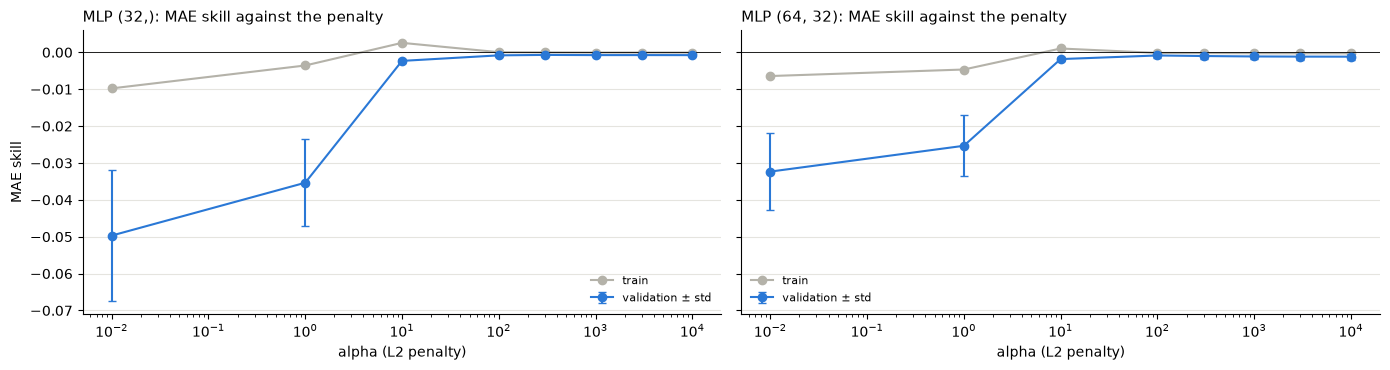

In [8]:
make_mlp = lambda **p: make_pipeline(StandardScaler(), MLPRegressor(max_iter=300, early_stopping=True, random_state=RANDOM_STATE, **p))
MLP_SIZES = [(32,), (64, 32)]
mlp_cv = val_tune(make_mlp, {"hidden_layer_sizes": MLP_SIZES, "alpha": [0.01, 1.0, 10.0, 100.0, 300.0, 1000.0, 3000.0, 10000.0]})
p_mlp = best_params(mlp_cv, ["hidden_layer_sizes", "alpha"])
MLP_RET = f"MLP {p_mlp}"
final_report(MLP_RET, make_mlp(**p_mlp))

fig, ax = plt.subplots(1, 2, figsize=(14, 3.8), sharey=True)
for a, size in zip(ax, MLP_SIZES):
    t = mlp_cv[mlp_cv["hidden_layer_sizes"].map(str) == str(size)].sort_values("alpha")
    a.plot(t["alpha"], t["train_skill"], "o-", color=GREY, label="train")
    a.errorbar(t["alpha"], t["val_skill"], yerr=t["val_skill_std"], fmt="o-", color=BLUE, capsize=3, label="validation ± std")
    a.axhline(0, color="k", lw=0.6)
    a.set_xscale("log")
    a.set_xlabel("alpha (L2 penalty)")
    a.legend(frameon=False, fontsize=8)
    tidy(a, f"MLP {size}: MAE skill against the penalty")
ax[0].set_ylabel("MAE skill")
plt.tight_layout()
plt.show()

### 3.2 LSTM on the 168-hour sequence

The settings of `model_test.ipynb` (hidden 64, 2 layers, dropout 0.2, lr 10⁻³, at most 30 epochs, patience 5), with three changes: the window-normalized channels of 1.4, the fair validation of section 2 with 5 seeds, and the **Huber** loss next to MSE (README task 7), so that the few extreme hours weigh less.

LSTM, MSE loss                                MAE=0.3195  skill=-0.0006  R2oos=-0.0005  IC=+0.004  DayDir=0.498 (p=0.56)  DayBalAcc=0.498
LSTM, Huber loss                              MAE=0.3195  skill=-0.0006  R2oos=-0.0005  IC=+0.004  DayDir=0.496 (p=0.61)  DayBalAcc=0.495


,epochs,val MAE_skill,val R2_oos,val IC,"test R2_oos, single seeds",seconds
"LSTM, MSE loss",4,-0.0010,-0.0017,-0.0153,-0.0008 ± 0.0001,11
"LSTM, Huber loss",4,-0.0004,-0.0005,-0.0012,-0.0007 ± 0.0001,5


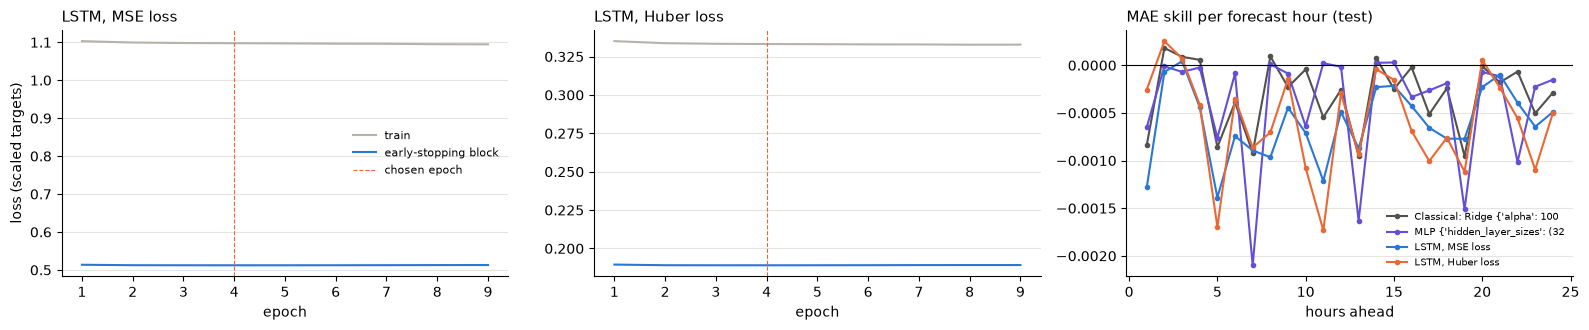

In [9]:
y_sd = Ytr.std()
LSTM_RET_KW = dict(hidden_size=64, num_layers=2, dropout=0.2)
TRAIN_KW = dict(epochs=30, patience=5, lr=1e-3, weight_decay=1e-4, batch=512)
lstm_runs = {}
for loss in ("mse", "huber"):
    name = f"LSTM, {'MSE' if loss == 'mse' else 'Huber'} loss"
    make_net = lambda: RecurrentNet("lstm", len(CHANNELS), n_out=24, **LSTM_RET_KW)
    t0 = time.time()
    pv, ep, hist, _ = early_stop_fit(make_net, S["train"], Ytr, S["val"], scale=y_sd, split=es_split("train"), loss=loss,
                                     **TRAIN_KW)
    preds = refit_net(make_net, S["tv"], Ytv, S["test"], ep, scale=y_sd, loss=loss, **TRAIN_KW)
    final_report(name, pred=np.mean(preds, axis=0))
    lstm_runs[name] = {"epochs": ep, "hist": hist, **{f"val {k}": v for k, v in metrics(Yva, pv).items() if k in ("MAE_skill", "R2_oos", "IC")},
                      "test R2_oos, single seeds": seed_spread(Yte, preds, U.r2_oos), "seconds": round(time.time() - t0)}
display(pd.DataFrame.from_dict(lstm_runs, orient="index").drop(columns="hist").round(4))

fig, ax = plt.subplots(1, 3, figsize=(16, 3.4))
for a, (name, r) in zip(ax, lstm_runs.items()):
    a.plot(range(1, len(r["hist"]["train"]) + 1), r["hist"]["train"], color=GREY, label="train")
    a.plot(range(1, len(r["hist"]["val"]) + 1), r["hist"]["val"], color=BLUE, label="early-stopping block")
    a.axvline(r["epochs"], color=ORANGE, ls="--", lw=0.8, label="chosen epoch")
    a.set_xlabel("epoch")
    tidy(a, name)
ax[0].set_ylabel("loss (scaled targets)")
ax[0].legend(frameon=False, fontsize=8)
mae0_h = np.abs(Yte).mean(axis=0)
for (name, pred), c in zip([(k, v) for k, v in test_preds.items() if not k.startswith("Baseline")], [INK, PURPLE, BLUE, ORANGE]):
    ax[2].plot(range(1, 25), 1 - np.abs(Yte - pred).mean(axis=0) / mae0_h, marker=".", color=c, label=name[:30])
ax[2].axhline(0, color="k", lw=0.8)
ax[2].set_xlabel("hours ahead")
ax[2].legend(frameon=False, fontsize=7)
tidy(ax[2], "MAE skill per forecast hour (test)")
plt.tight_layout()
plt.show()

### 3.3 Comparison on the test block

The network chosen is the one with the best validation MAE skill.

In [10]:
summary = pd.DataFrame(results).drop_duplicates("Model", keep="last").set_index("Model")
cols = ["MAE", "RMSE", "MAE_skill", "R2_oos", "IC", "HourDirAcc", "DayDirAcc_indep", "p_value", "DayBalAcc_indep"]
display(summary[cols].sort_values("MAE").round(4))

ret_val_skill = {MLP_RET: mlp_cv.loc[0, "val_skill"], **{k: v["val MAE_skill"] for k, v in lstm_runs.items()}}
RET_CHOSEN = max(ret_val_skill, key=ret_val_skill.get)
nets = summary.loc[list(ret_val_skill)]
print(f"chosen on validation: {RET_CHOSEN} (validation MAE skill {ret_val_skill[RET_CHOSEN]:+.4f})")
SUMMARY.append({"question": "24 hourly returns", "network (chosen without the test)": f"{RET_CHOSEN} (of MLP, LSTM with MSE / Huber)",
                "test result": f"MAE skill {nets.loc[RET_CHOSEN, 'MAE_skill']:+.4f} (all networks {nets['MAE_skill'].min():+.4f} to "
                               f"{nets['MAE_skill'].max():+.4f}), IC {nets.loc[RET_CHOSEN, 'IC']:+.3f}",
                "classical reference (refitted here)": f"Ridge: MAE skill {summary.loc[f'Classical: Ridge {p_ridge}', 'MAE_skill']:+.4f}"})

,MAE,RMSE,MAE_skill,R2_oos,IC,HourDirAcc,DayDirAcc_indep,p_value,DayBalAcc_indep
Model,,,,,,,,,
Baseline: zero,0.3193,0.4925,-0.0000,0.0000,NaN,0.4960,0.4994,0.5277,0.5000
Baseline: mean per hour,0.3194,0.4926,-0.0003,-0.0003,0.0000,0.5027,0.5006,0.5000,0.5000
Classical: Ridge {'alpha': 100000.0},0.3194,0.4926,-0.0003,-0.0003,0.0012,0.5017,0.5006,0.5000,0.5000
"MLP {'hidden_layer_sizes': (32,), 'alpha': 300.0}",0.3194,0.4926,-0.0004,-0.0004,0.0000,0.5017,0.5006,0.5000,0.5000
"LSTM, Huber loss",0.3195,0.4926,-0.0006,-0.0005,0.0044,0.5017,0.4958,0.6094,0.4952
"LSTM, MSE loss",0.3195,0.4926,-0.0006,-0.0005,0.0036,0.5020,0.4982,0.5552,0.4976


chosen on validation: LSTM, Huber loss (validation MAE skill -0.0004)


### 3.4 What we see

**Answer: no. Every network ends at the zero forecast, like every classical model.**

- Test MAE skill −0.0006 (both LSTMs) and −0.0004 (MLP), IC ≤ 0.005, daily direction 49.6–50.1% (p ≥ 0.50). The LSTM with Huber loss is chosen; its R²_oos interval is [−0.0011, +0.0001] (section 7).
- **The fixes change nothing:** early stopping stops at 4 epochs, and MSE and Huber give the same test result.
- **The MLP:** the more freedom, the worse on validation (MAE skill −0.0007 at alpha 300, −0.050 at alpha 0.01), as in versions 1–2.

## 4. The direction of the next hour

**Question.** Will the next hour go up or down; can a sequence model see more than the reversal of the last hour? **To beat:** Gradient Boosting, AUC 0.533, and the reversal rule ("the next hour goes the opposite way"), 0.528 (`classical-models.ipynb` §5).

**Models:** the reversal rule, Gradient Boosting on the 42 base features and an LSTM classifier on the 168-hour sequence (cross-entropy, fair validation of section 2). Neighbouring origins predict different hours here, so Gradient Boosting and the LSTM are also trained on **every origin**. **Metrics** on every test hour (≈ 19,800): AUC, and the accuracy of the 10% most confident calls with a binomial test.

,val AUC,AUC,accuracy top 10%,p-value,"test AUC, single seeds"
Reversal rule,0.5460,0.5278,0.5459,2.4e-05,
"Classical: GB classifier {'learning_rate': 0.03, 'max_depth': 3, 'min_samples_leaf': 200}",0.5535,0.5328,0.5393,2.5e-04,
"Classical: GB classifier, every origin {'learning_rate': 0.03, 'max_depth': 3, 'min_samples_leaf': 200}",0.5687,0.5409,0.5590,8.2e-08,
LSTM classifier (1 epochs),0.5418,0.5135,0.5176,6.1e-02,0.5123 ± 0.0033
"LSTM classifier, every origin (25 epochs)",0.5574,0.5376,0.5993,4.3e-19,0.5361 ± 0.0014


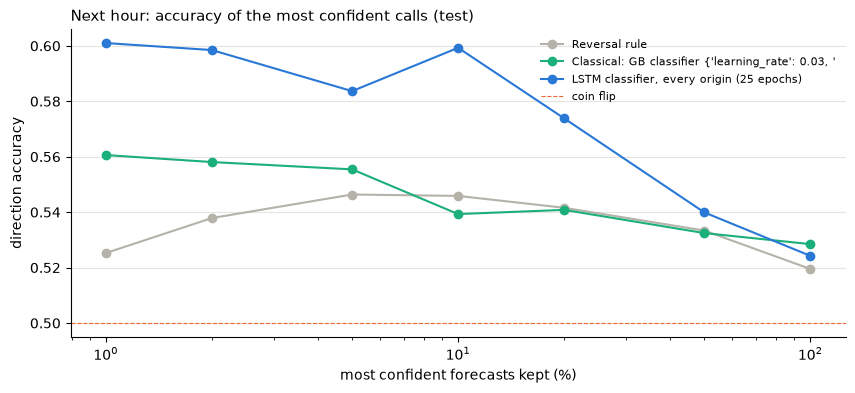

In [11]:
y1 = {k: Y[k][:, 0] for k in P}                                      # the next hour's return
up = {k: (v > 0).astype(np.float32) for k, v in y1.items()}


def direction_row(score, y):
    nz = y != 0
    score, y = score[nz], y[nz]
    centred = score - np.median(score)
    top = np.argsort(-np.abs(centred))[:len(score) // 10]
    hits = (centred[top] > 0) == (y[top] > 0)
    return {"AUC": roc_auc_score(y > 0, score), "accuracy top 10%": hits.mean(),
            "p-value": stats.binomtest(int(hits.sum()), len(top), 0.5, alternative="greater").pvalue}


def tune_by_auc(make, grid, Xa, ya, Xv, yv):
    # Fit each setting on (Xa, ya > 0), AUC on the validation block -> (best setting, its AUC)
    grid = list(ParameterGrid(grid))
    auc = [roc_auc_score(yv > 0, make(**p).fit(Xa, ya > 0).predict_proba(Xv)[:, 1]) for p in grid]
    return grid[int(np.argmax(auc))], max(auc)


dir_rows, dir_scores = {}, {}


def add_dir(name, val_auc, score, seed_scores=None):
    dir_scores[name] = score
    dir_rows[name] = {"val AUC": val_auc, **direction_row(score, y1["test"]),
                      "test AUC, single seeds": seed_spread(y1["test"] > 0, seed_scores, roc_auc_score) if seed_scores else ""}


add_dir("Reversal rule", roc_auc_score(y1["val"] > 0, -FEAT["ret_lag1"].values[P["val"]]), -FEAT["ret_lag1"].values[P["test"]])

make_clf = lambda **p: HistGradientBoostingClassifier(early_stopping=False, max_iter=200, random_state=RANDOM_STATE, **p)
CLF_GRID = {"learning_rate": [0.03, 0.1], "max_depth": [2, 3], "min_samples_leaf": [200, 1000]}
for tag, tr, tv in [("", "train", "tv"), (", every origin", "train1", "tv1")]:
    p, auc = tune_by_auc(make_clf, CLF_GRID, Xw(tr, BASE), y1[tr], Fva, y1["val"])
    add_dir(f"Classical: GB classifier{tag} {p}", auc, make_clf(**p).fit(Xw(tv, BASE), y1[tv] > 0).predict_proba(Fte)[:, 1])
GB_DIR = [k for k in dir_rows if k.startswith("Classical: GB classifier {")][0]

S["train1"], S["tv1"] = seq("train1"), seq("tv1")                   # every origin (also used in section 5)
make_lstm_clf = lambda: RecurrentNet("lstm", len(CHANNELS), hidden_size=64, num_layers=2, dropout=0.2, n_out=1)
CLF_KW = dict(loss="bce", epochs=30, patience=5, lr=1e-3, weight_decay=1e-4, batch=512)
lstm_clf_hist = {}
for tag, tr, tv in [("", "train", "tv"), (", every origin", "train1", "tv1")]:
    pv, ep, lstm_clf_hist[tag], _ = early_stop_fit(make_lstm_clf, S[tr], up[tr], S["val"], split=es_split(tr), **CLF_KW)
    logits = refit_net(make_lstm_clf, S[tv], up[tv], S["test"], ep, **CLF_KW)
    add_dir(f"LSTM classifier{tag} ({ep} epochs)", roc_auc_score(up["val"], pv), np.mean(logits, axis=0), logits)

dir_tab = pd.DataFrame.from_dict(dir_rows, orient="index")
display(dir_tab.assign(**{"p-value": dir_tab["p-value"].map("{:.1e}".format)}).round(4))

SHARES = [0.01, 0.02, 0.05, 0.1, 0.2, 0.5, 1.0]


def confidence_curve(score, y):
    # Direction accuracy on the q most confident forecasts (|score - median| largest), zero returns left out
    nz = y != 0
    c = score[nz] - np.median(score[nz])
    hits = ((c > 0) == (y[nz] > 0))[np.argsort(-np.abs(c))]
    return [hits[:max(1, int(len(hits) * q))].mean() for q in SHARES]


nets_dir = [k for k in dir_rows if not k.startswith(("Reversal", "Classical"))]
DIR_CHOSEN = max(nets_dir, key=lambda k: dir_rows[k]["val AUC"])
fig, ax = plt.subplots(figsize=(10, 4))
for k, c in zip(["Reversal rule", GB_DIR, DIR_CHOSEN], [GREY, AQUA, BLUE]):
    ax.plot([100 * q for q in SHARES], confidence_curve(dir_scores[k], y1["test"]), "o-", color=c, label=k[:50])
ax.axhline(0.5, color=ORANGE, ls="--", lw=0.8, label="coin flip")
ax.set_xscale("log")
ax.set_xlabel("most confident forecasts kept (%)")
ax.set_ylabel("direction accuracy")
ax.legend(frameon=False, fontsize=8)
tidy(ax, "Next hour: accuracy of the most confident calls (test)")
plt.show()

SUMMARY.append({"question": "direction of the next hour", "network (chosen without the test)": f"{DIR_CHOSEN.split(' {')[0]} (best validation AUC)",
                "test result": f"AUC {dir_rows[DIR_CHOSEN]['AUC']:.3f}, top 10% right {dir_rows[DIR_CHOSEN]['accuracy top 10%']:.1%} "
                               f"(p = {dir_rows[DIR_CHOSEN]['p-value']:.0e})",
                "classical reference (refitted here)": f"GB AUC {dir_rows[GB_DIR]['AUC']:.3f}; reversal rule {dir_rows['Reversal rule']['AUC']:.3f}"})

### 4.1 What we see

**Answer: a tie. The LSTM reaches Gradient Boosting only with every origin, and the gain comes from the rows, not the network.**

- The LSTM on every origin (25 epochs) is chosen: test AUC **0.538**, its 10% most confident calls right **59.9%** (p = 4×10⁻¹⁹). Against Gradient Boosting (0.533): +0.005, interval [−0.002, +0.012] (section 7).
- On every 6th origin the same LSTM stops after 1 epoch with AUC 0.514, below the reversal rule. Every origin lifts Gradient Boosting too, to 0.541, the best test AUC.
- The confident calls of the LSTM (59.9% against 53.9–55.9% for Gradient Boosting) are its one lead, not tested here. The effect is small and comes before trading costs.

## 5. The size of each hourly move (main experiment)

**Question.** How large will each of the next 24 hourly moves be? Target: **|r|** of each hour, in %, judged by R². The size of the moves is strongly autocorrelated, so this is where the classical models find the clearest hourly signal.

**To beat:** Gradient Boosting in long format, **(a) fitted once** and **(b) refitted every month** (the best classical model, `classical-models.ipynb` §6.5), refitted here on the same rows.

| Experiment | Question |
|---|---|
| **inputs** (5.1) | which per-hour columns to use, chosen with Gradient Boosting |
| **MLP** (5.2) | on the same rows as Gradient Boosting, is a network better than trees? |
| **LSTM** (5.3) | can a network build its own features from the raw week? |
| **+ hour features** (5.3) | does the LSTM gain from knowing which hours it predicts? |
| **+ volume attention** (5.3) | do the most traded hours of the week carry information the last hidden state loses? |
| **scale-free** (5.2, 5.3) | is it easier to predict \|r\| relative to last week's level, which fell from train to test? |
| **every origin, monthly refits** (5.4) | does the MLP gain from 6× more rows, or from being refitted every month? |
| **monthly fine-tuning** (5.4b) | does the LSTM gain from being kept up to date? |
| **ensembles** (5.5) | do networks and trees make errors that cancel? |

### 5.1 Inputs and the classical references

Gradient Boosting is tuned on the base columns with the grid of `classical-models.ipynb` §6.1; with that setting, each candidate set of inputs is scored on validation and the best (`CHOSEN_SET`) is used by Gradient Boosting and the MLP. **(a) Fitted once:** with `CHOSEN_SET` on train + validation.

In [12]:
ya = {k: yl(k) for k in ("train", "val", "test", "tv")}
abs_sd = ya["train"].std()


def abs_baselines(block):
    p = np.repeat(P[block], 24)
    h_ = np.tile(np.arange(1, 25), len(P[block]))
    return {"Baseline: training mean": np.full(len(p), ya["train"].mean()),
            "Baseline: last week": week_abs[p],
            "Baseline: last week x hour profile": rule_abs(block)}


make_abs_gb = lambda **p: make_gb(min_samples_leaf=1000, **p)
print("Gradient Boosting on the base columns, validation block")
_, p_abs_gb = tune(make_abs_gb, {"learning_rate": [0.05, 0.1], "max_depth": [2, 3, 6]},
                   Xl("train", BASE), ya["train"], Xl("val", BASE), ya["val"], vol_scores)

feat_rows = {}
for name, (cols, hcols) in FSETS.items():                           # the setting above, fixed: only the inputs change
    Xtr_l, Xva_l = Xl("train", cols, hcols), Xl("val", cols, hcols)
    feat_rows[name] = {"n_features": Xtr_l.shape[1],
                       "val R2": U.r2(ya["val"], make_abs_gb(**p_abs_gb).fit(Xtr_l, ya["train"]).predict(Xva_l)),
                       "test R2": U.r2(ya["test"], make_abs_gb(**p_abs_gb).fit(Xl("tv", cols, hcols), ya["tv"])
                                       .predict(Xl("test", cols, hcols)))}
del Xtr_l, Xva_l
feat_tab = pd.DataFrame.from_dict(feat_rows, orient="index")
CHOSEN_SET = feat_tab.drop("base")["val R2"].idxmax()
print("Input sets, Gradient Boosting fitted once (test R2 for information only)")
display(feat_tab.round(4))
print(f"chosen on validation: {CHOSEN_SET}")

COLS, HCOLS = FSETS[CHOSEN_SET]
XA = {k: Xl(k, COLS, HCOLS) for k in ("train", "val", "test", "tv")}
GB_ABS = "Classical: GB, fitted once"
abs_val = {**abs_baselines("val"), GB_ABS: make_abs_gb(**p_abs_gb).fit(XA["train"], ya["train"]).predict(XA["val"])}
abs_test = {**abs_baselines("test"), GB_ABS: make_abs_gb(**p_abs_gb).fit(XA["tv"], ya["tv"]).predict(XA["test"])}
abs_seeds = {}

Gradient Boosting on the base columns, validation block


,learning_rate,max_depth,score,MAE,corr,seconds
0,0.10,6,0.0966,0.2224,0.3135,1.7
1,0.05,6,0.0959,0.2241,0.3127,1.8
2,0.05,3,0.0932,0.2260,0.3089,1.3
3,0.10,3,0.0921,0.2238,0.3061,1.3
4,0.10,2,0.0915,0.2258,0.3058,1.2
5,0.05,2,0.0901,0.2288,0.3067,1.2


Input sets, Gradient Boosting fitted once (test R2 for information only)


,n_features,val R2,test R2
base,47,0.0966,0.1292
base + B3,52,0.0947,0.1295
base + B3 + B4,55,0.0876,0.1277
base + B3 + B5,57,0.0941,0.1311
base + B3 + B4 + B5,60,0.0894,0.1298
base + B3 + B4 + B5 + recent profile,61,0.0923,0.1377


chosen on validation: base + B3


**(b) Refitted every month.** For every month of validation or test, Gradient Boosting is refitted on every 6th origin whose target hours ended before the month, with weight `0.5 ** (age in months / 12)` (half-life 12 months, chosen in `classical-models.ipynb` §6.5). The MLP (5.4) and the LSTM (5.4b) use the same pool and weights.

In [13]:
pool = np.arange(len(origins))[::STRIDE]                             # every 6th origin of the whole series
P["pool"], Y["pool"], D["pool"] = pos_all[pool], y_all[pool], origins[pool]
X_pool, y_pool = Xl("pool", COLS, HCOLS), yl("pool")
pool_end, pool_origin = np.repeat(day_end[pool], 24), np.repeat(origins[pool], 24)
REFIT_CHOSEN = "Monthly, half-life 12 months"                       # chosen on validation in classical-models.ipynb, 6.5
REFIT = {REFIT_CHOSEN: {"half_life": 12}}


def month_fit_rows(start, window=None, half_life=None):
    fit = pool_end < start                                           # targets known before the month
    if window:
        fit &= pool_origin >= start - pd.DateOffset(months=window)
    w = 0.5 ** ((start - pool_origin[fit]) / pd.Timedelta(days=30.44) / half_life) if half_life else None
    return fit, w


def refit_monthly(block, X_b, X_fit, fit_predict, y_fit=None, **kw):
    # Every month of the block: fit_predict(X, y, weights, X_month) on the pool rows known before the month
    # (y_fit: the target of the pool rows, |r| by default)
    y_fit = y_pool if y_fit is None else y_fit
    org = np.repeat(D[block], 24)
    pred = np.empty(len(X_b))
    for m in pd.period_range(D[block][0], D[block][-1], freq="M"):
        start = m.start_time
        fit, w = month_fit_rows(start, **kw)
        rows_m = (org >= start) & (org < (m + 1).start_time)
        pred[rows_m] = fit_predict(X_fit[fit], y_fit[fit], w, X_b[rows_m])
    return pred


gb_month = lambda X, y, w, X_new: make_abs_gb(**p_abs_gb).fit(X, y, sample_weight=w).predict(X_new)
t0 = time.time()
GB_REFIT = f"Classical: GB, {REFIT_CHOSEN.lower()}"
abs_val[GB_REFIT] = refit_monthly("val", XA["val"], X_pool, gb_month, **REFIT[REFIT_CHOSEN])
abs_test[GB_REFIT] = refit_monthly("test", XA["test"], X_pool, gb_month, **REFIT[REFIT_CHOSEN])
refit_tab = pd.DataFrame({"val R2": {"Fit once": U.r2(ya["val"], abs_val[GB_ABS]), REFIT_CHOSEN: U.r2(ya["val"], abs_val[GB_REFIT])},
                          "test R2": {"Fit once": U.r2(ya["test"], abs_test[GB_ABS]), REFIT_CHOSEN: U.r2(ya["test"], abs_test[GB_REFIT])}})
print(f"{REFIT_CHOSEN} ({time.time() - t0:.0f} s)")
display(refit_tab.round(4))

Monthly, half-life 12 months (884 s)


,val R2,test R2
Fit once,0.0947,0.1295
"Monthly, half-life 12 months",0.1005,0.1479


### 5.2 MLP in long format

The columns of `CHOSEN_SET`, standardized; grid of size and weight decay, dropout 0.1, at most 40 epochs. A second MLP with the same setting learns the **scale-free target** `|r_h| / s_o` (`s_o`: last week's average |r|), its forecast multiplied back. The better of the two on validation (`MLP_WIN`) goes on to 5.4. `NET` stores each network's builder, input and target so that 5.4 and 5.4b reuse them.

In [14]:
sc_abs = StandardScaler().fit(XA["train"])
XA_s = {k: sc_abs.transform(v).astype(np.float32) for k, v in XA.items()}
ABS_MLP_KW = dict(epochs=40, patience=5, lr=1e-3, batch=2048)


def level(block, long=True):
    # s_o: last week's average |r| at each origin (the 168 hours up to it), per long-format row or per origin
    s = week_abs[P[block]]
    return np.repeat(s, 24) if long else s[:, None]


# target of a network and its inverse, f(y or forecast, block, long): |r| itself, or the scale-free |r| / s_o
RAW_TARGET = (lambda y, b, long: y, lambda p, b, long: p)
SCALE_FREE = (lambda y, b, long: y / level(b, long), lambda p, b, long: p * level(b, long))
sf_sd = (ya["train"] / level("train")).std()                         # train std of the scale-free target
NET = {}   # name -> spec, best run, input X(block), long or per origin, target, target scale, training options


def net_y(name, block):
    # the training target of network `name` on a block: long-format rows, or (origins, 24)
    n = NET[name]
    return n["target"][0](yl(block) if n["long"] else np.abs(Y[block]), block, n["long"])


def net_abs(name, pred, block):
    # a forecast of network `name` back to |r|, flattened origin by origin (the rows of the long format)
    n = NET[name]
    out = n["target"][1](pred, block, n["long"]).reshape(-1)
    assert out.shape == (len(P[block]) * 24,), (name, block, out.shape)
    return out


def fit_net(name, states=False):
    # Network `name` of NET. A variant without a run of its own (no grid) first gets its number of epochs and its
    # validation forecast (early_stop_fit); then N_SEEDS refits on train + validation -> abs_val, abs_seeds
    # (states: also keep the weights of the refits, the start of the monthly fine-tuning in 5.4b)
    n = NET[name]
    if "val" not in n["best"]:
        make_net, tkw = n["spec"](**n["best"]["params"])
        pv, ep, hist, state = early_stop_fit(make_net, n["X"]("train"), net_y(name, "train"), n["X"]("val"), n["scale"],
                                             split=es_split("train", n["long"]), **{**n["kw"], **tkw})
        n["best"] = {**n["best"], "val": pv, "epochs": ep, "hist": hist, "state": state}
    out = refit_best(n["spec"], n["best"], n["X"]("tv"), net_y(name, "tv"), n["X"]("test"), n["scale"],
                     return_states=states, **n["kw"])
    preds, n["states"] = out if states else (out, None)
    abs_val[name] = net_abs(name, n["best"]["val"], "val")
    abs_seeds[name] = [net_abs(name, q, "test") for q in preds]


def mlp_x(block):
    # input of the MLP: the columns of CHOSEN_SET, standardized with the train block
    return XA_s[block] if block in XA_s else sc_abs.transform(Xl(block, COLS, HCOLS)).astype(np.float32)


def mlp_abs_spec(hidden, weight_decay):
    return (lambda: MLPNet(XA_s["train"].shape[1], hidden, n_out=1, dropout=0.1)), {"weight_decay": weight_decay}


_, mlp_abs_best = nn_grid(mlp_abs_spec, {"hidden": [(64, 32), (256, 128)], "weight_decay": [1e-4, 1e-2]},
                          XA_s["train"], ya["train"], XA_s["val"], ya["val"], vol_scores, scale=abs_sd,
                          split=es_split("train", long=True), **ABS_MLP_KW)
MLP_ABS = f"MLP, long format {mlp_abs_best['params']}"
NET[MLP_ABS] = dict(spec=mlp_abs_spec, best=mlp_abs_best, X=mlp_x, long=True, target=RAW_TARGET, scale=abs_sd, kw=ABS_MLP_KW)
fit_net(MLP_ABS)

# the same setting with the scale-free target: no grid of its own
MLP_SF = f"MLP, long format, scale-free {mlp_abs_best['params']}"
NET[MLP_SF] = {**NET[MLP_ABS], "best": {"params": mlp_abs_best["params"]}, "target": SCALE_FREE, "scale": sf_sd}
fit_net(MLP_SF)
MLP_WIN = max([MLP_ABS, MLP_SF], key=lambda k: U.r2(ya["val"], abs_val[k]))
display(pd.DataFrame({k: {"val R2": U.r2(ya["val"], abs_val[k]), "epochs": NET[k]["best"]["epochs"]} for k in (MLP_ABS, MLP_SF)}).T.round(4))
print(f"better on validation (every origin and monthly refits in 5.4): {MLP_WIN}")

,hidden,weight_decay,score,MAE,corr,epochs,seconds
3,"(256, 128)",0.0100,0.0945,0.2195,0.3107,3,2.0
2,"(256, 128)",0.0001,0.0945,0.2196,0.3106,3,2.0
0,"(64, 32)",0.0001,0.0931,0.2232,0.3077,8,3.8
1,"(64, 32)",0.0100,0.0929,0.2232,0.3074,8,3.9


,val R2,epochs
"MLP, long format {'hidden': (256, 128), 'weight_decay': 0.01}",0.0945,3.0
"MLP, long format, scale-free {'hidden': (256, 128), 'weight_decay': 0.01}",0.0958,2.0


better on validation (every origin and monthly refits in 5.4): MLP, long format, scale-free {'hidden': (256, 128), 'weight_decay': 0.01}


### 5.3 LSTM on the 168-hour sequence

The LSTM of `model_test.ipynb` (2 layers, dropout 0.2), grid of hidden sizes, at most 60 epochs with patience 8, one output per hour ahead. It knows the clock of the hours it read, but not which hours it predicts.

In [15]:
LSTM_KW = dict(epochs=60, patience=8, lr=1e-3, weight_decay=1e-4, batch=512)
r2_flat = lambda y, p: vol_scores(np.ravel(y), np.ravel(p))


def lstm_abs_spec(hidden_size):
    return (lambda: RecurrentNet("lstm", len(CHANNELS), hidden_size=hidden_size, num_layers=2, dropout=0.2, n_out=24)), {}


_, lstm_abs_best = nn_grid(lstm_abs_spec, {"hidden_size": [32, 64, 128]}, S["train"], np.abs(Y["train"]), S["val"], np.abs(Y["val"]),
                           r2_flat, scale=abs_sd, split=es_split("train"), **LSTM_KW)
LSTM_ABS = f"LSTM {lstm_abs_best['params']}"
NET[LSTM_ABS] = dict(spec=lstm_abs_spec, best=lstm_abs_best, X=lambda b: S[b] if b in S else seq(b), long=False,
                     target=RAW_TARGET, scale=abs_sd, kw=LSTM_KW)
fit_net(LSTM_ABS, states=True)

,hidden_size,score,MAE,corr,epochs,seconds
2,128,0.0999,0.2229,0.3173,31,24.9
1,64,0.0959,0.2223,0.3105,39,9.0
0,32,0.0879,0.2219,0.2969,36,4.6


**LSTM + hour features** (`FutureHeadLSTM`). For each predicted hour, a small head shared by the 24 hours reads the last hidden state and the features of that hour: `h_ahead`, clock, `tgt_weekend`, `tgt_hour_profile_recent` and B5. Same grid and training. The best of the four LSTMs of this section on validation (`LSTM_WIN`) is fine-tuned in 5.4b.

In [16]:
FUT = H_BASE + ["tgt_weekend"] + RECENT + B5                         # features of each predicted hour
_f = Xl("train", [], FUT)
FUT_MU, FUT_SD = _f.mean(axis=0), np.where(_f.std(axis=0) > 0, _f.std(axis=0), 1.0)
del _f


def seq_fut(block, s=None):
    # one row per origin: the standardized sequence (that of 1.4 unless s is given), then the standardized features of
    # its 24 predicted hours
    s = S[block] if s is None else s
    f = ((Xl(block, [], FUT) - FUT_MU) / FUT_SD).reshape(len(P[block]), -1)
    return np.hstack([s.reshape(len(s), -1), f]).astype(np.float32)


SF = {k: seq_fut(k) for k in ("train", "val", "test", "tv")}


def lstm_fut_spec(hidden_size):
    return (lambda: FutureHeadLSTM(len(CHANNELS), len(FUT), hidden_size=hidden_size, num_layers=2, dropout=0.2)), {}


_, lstm_fut_best = nn_grid(lstm_fut_spec, {"hidden_size": [32, 64, 128]}, SF["train"], np.abs(Y["train"]), SF["val"],
                           np.abs(Y["val"]), r2_flat, scale=abs_sd, split=es_split("train"), **LSTM_KW)
LSTM_FUT = f"LSTM + hour features {lstm_fut_best['params']}"
NET[LSTM_FUT] = dict(spec=lstm_fut_spec, best=lstm_fut_best, X=lambda b: SF[b] if b in SF else seq_fut(b), long=False,
                     target=RAW_TARGET, scale=abs_sd, kw=LSTM_KW)
fit_net(LSTM_FUT, states=True)

,hidden_size,score,MAE,corr,epochs,seconds
1,64,0.1161,0.2222,0.3440,17,4.4
0,32,0.1133,0.2256,0.3415,23,2.9
2,128,0.1130,0.2276,0.3443,17,14.9


**LSTM + hour features, scale-free.** The same network with the hidden size chosen above, without having to learn the level of volatility: `ret`, `abs_ret` and `hl_range` are divided by the window's average |r| (`s_o`), `log s_o` is an 11th channel, and the target is `|r_h| / s_o`. One run of section 2, no grid.

In [17]:
def raw_seq_sf(pos):
    # raw_seq with ret, abs_ret and hl_range divided by the window's own average |r| (s_o: the 168 hours up to the
    # origin, = week_abs), and log s_o as an 11th channel, constant over the window
    x, lvl = raw_seq(pos), week_abs[pos].astype(np.float32)
    x[..., :3] /= lvl[:, None, None]
    return np.concatenate([x, np.broadcast_to(np.log(lvl)[:, None, None], x.shape[:2] + (1,))], axis=2)


_tr = raw_seq_sf(P["train"]).reshape(-1, len(CHANNELS) + 1)
SF_MU, SF_SD = _tr.mean(axis=0), _tr.std(axis=0)
del _tr


def seq_sf(block):
    return np.clip((raw_seq_sf(P[block]) - SF_MU) / SF_SD, -10, 10).astype(np.float32)


SFS = {k: seq_fut(k, seq_sf(k)) for k in ("train", "val", "test", "tv")}


def lstm_sf_spec(hidden_size):
    return (lambda: FutureHeadLSTM(len(CHANNELS) + 1, len(FUT), hidden_size=hidden_size, num_layers=2, dropout=0.2)), {}


LSTM_SF = f"LSTM + hour features, scale-free {lstm_fut_best['params']}"
NET[LSTM_SF] = dict(spec=lstm_sf_spec, best={"params": lstm_fut_best["params"]},
                    X=lambda b: SFS[b] if b in SFS else seq_fut(b, seq_sf(b)), long=False, target=SCALE_FREE, scale=sf_sd, kw=LSTM_KW)
fit_net(LSTM_SF, states=True)

**LSTM + hour features + volume attention** (`VolumeAttentionLSTM`). The LSTM + hour features sees the week only through its last hidden state. Here the head also reads an **attention** average of the 168 hidden states, weighted by a **mask of the traded volume**:

- α_t = softmax_t(β · v_t), with v_t the `volume_vs_window` channel of hour *t*;
- β is learned from 1 (β = 0: plain average; β > 0: the busiest hours count most). Only β is learned, so the experiment tests the volume itself;
- everything else is that of the LSTM + hour features. One run of section 2, no grid.

Under the table: the β of each final network and the share of the weight on the 10% most traded hours of each test window (10% for a plain average).

,val R2,epochs
LSTM {'hidden_size': 128},0.0999,31.0
LSTM + hour features {'hidden_size': 64},0.1161,17.0
"LSTM + hour features, scale-free {'hidden_size': 64}",0.1127,16.0
LSTM + hour features + volume attention {'hidden_size': 64},0.1200,24.0


best on validation (monthly fine-tuning in 5.4b): LSTM + hour features + volume attention {'hidden_size': 64}
beta of the 5 final networks: +0.91, +0.92, +0.92, +0.93, +0.92
share of the attention on the 10% most traded hours of each test window: 38.2%, 38.3%, 38.6%, 38.8%, 38.5% (plain average: 10%)


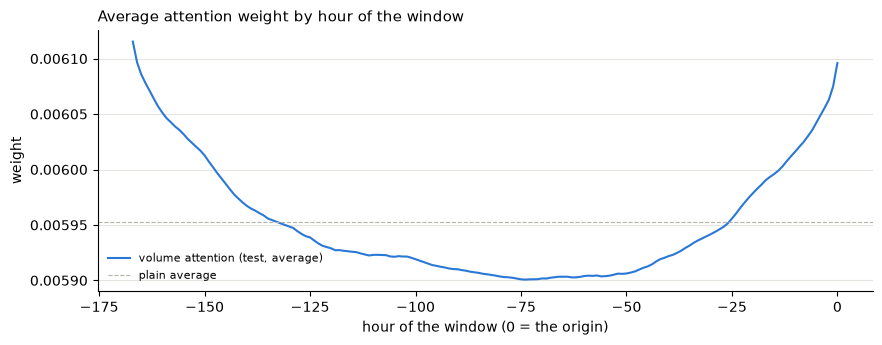

In [18]:
VOL_CH = CHANNELS.index("volume_vs_window")


def lstm_att_spec(hidden_size):
    return (lambda: VolumeAttentionLSTM(len(CHANNELS), len(FUT), hidden_size=hidden_size, num_layers=2, dropout=0.2,
                                        vol_channel=VOL_CH)), {}


LSTM_ATT = f"LSTM + hour features + volume attention {lstm_fut_best['params']}"
NET[LSTM_ATT] = {**NET[LSTM_FUT], "spec": lstm_att_spec, "best": {"params": lstm_fut_best["params"]}}
fit_net(LSTM_ATT, states=True)

LSTM_WIN = max([LSTM_ABS, LSTM_FUT, LSTM_SF, LSTM_ATT], key=lambda k: U.r2(ya["val"], abs_val[k]))
display(pd.DataFrame({k: {"val R2": U.r2(ya["val"], abs_val[k]), "epochs": NET[k]["best"]["epochs"]}
                      for k in (LSTM_ABS, LSTM_FUT, LSTM_SF, LSTM_ATT)}).T.round(4))
print(f"best on validation (monthly fine-tuning in 5.4b): {LSTM_WIN}")

# the attention mask of the final networks on the test windows
betas = np.array([st["beta"].item() for st in NET[LSTM_ATT]["states"]])
v_te = S["test"][..., VOL_CH]                                         # (origins, SEQ_HOURS)
top = v_te >= np.quantile(v_te, 0.9, axis=1, keepdims=True)          # the 10% most traded hours of each window
alphas = []
for b in betas:
    a = np.exp(b * (v_te - v_te.max(axis=1, keepdims=True)))
    alphas.append(a / a.sum(axis=1, keepdims=True))
print(f"beta of the {len(betas)} final networks: " + ", ".join(f"{b:+.2f}" for b in betas))
print("share of the attention on the 10% most traded hours of each test window: "
      + ", ".join(f"{(a * top).sum(axis=1).mean():.1%}" for a in alphas) + " (plain average: 10%)")

fig, ax = plt.subplots(figsize=(10, 3.4))
ax.plot(np.arange(-SEQ_HOURS + 1, 1), np.mean(alphas, axis=(0, 1)), color=BLUE, label="volume attention (test, average)")
ax.axhline(1 / SEQ_HOURS, color=GREY, ls="--", lw=0.8, label="plain average")
ax.set_xlabel("hour of the window (0 = the origin)")
ax.set_ylabel("weight")
ax.legend(frameon=False, fontsize=8)
tidy(ax, "Average attention weight by hour of the window")
plt.show()


### 5.4 Every origin and monthly refits of the MLP

**Every origin:** `MLP_WIN` trained on every origin of train, then of train + validation (in the previous run every origin changed Gradient Boosting and the LSTM by less than 0.001, so only the MLP is trained on it). **Monthly refits:** `MLP_WIN` trained from scratch every month on the pool of 5.1 (b), with its weights and the number of epochs of 5.2; one seed on validation, 5 on test.

In [19]:
# the MLP that was better on validation in 5.2, with its own input and target
MLP_ABS1 = f"{MLP_WIN}, every origin"
more_data = {}
for name, base in [(MLP_ABS1, MLP_WIN)]:
    t0 = time.time()
    n = NET[base]
    make_net, tkw = n["spec"](**n["best"]["params"])
    X1 = {k: n["X"](k) for k in ("train1", "tv1")}
    pv, ep, _, _ = early_stop_fit(make_net, X1["train1"], net_y(base, "train1"), n["X"]("val"), n["scale"],
                                  split=es_split("train1", n["long"]), **{**n["kw"], **tkw})
    abs_val[name] = net_abs(base, pv, "val")
    abs_seeds[name] = [net_abs(base, q, "test") for q in
                       refit_net(make_net, X1["tv1"], net_y(base, "tv1"), n["X"]("test"), ep, n["scale"], **{**n["kw"], **tkw})]
    more_data[name] = {"epochs": ep, "val R2": U.r2(ya["val"], abs_val[name]), "seconds": round(time.time() - t0)}
    del X1

# monthly refits of the MLP: the variant chosen for Gradient Boosting in 5.1, the number of epochs chosen in 5.2
t0 = time.time()
mlp_net = NET[MLP_WIN]
X_pool_s = sc_abs.transform(X_pool).astype(np.float32)
y_pool_net = net_y(MLP_WIN, "pool")                                  # the MLP's target on the pool rows
make_mlp_net, mlp_tkw = mlp_net["spec"](**mlp_net["best"]["params"])
mlp_kw = {k: v for k, v in {**mlp_net["kw"], **mlp_tkw}.items() if k not in ("epochs", "patience")}


def mlp_month(seed):
    def fit_predict(X, y, w, X_new):
        net, _ = train_net(make_mlp_net, X, y / mlp_net["scale"], epochs=mlp_net["best"]["epochs"], w=w, seed=seed, **mlp_kw)
        return predict_net(net, X_new) * mlp_net["scale"]
    return fit_predict


def mlp_refit(block, seed):
    return net_abs(MLP_WIN, refit_monthly(block, mlp_x(block), X_pool_s, mlp_month(seed), y_fit=y_pool_net,
                                          **REFIT[REFIT_CHOSEN]), block)


MLP_REFIT = f"{MLP_WIN.split(' {')[0]}, {REFIT_CHOSEN.lower()}"
abs_val[MLP_REFIT] = mlp_refit("val", RANDOM_STATE)
abs_seeds[MLP_REFIT] = [mlp_refit("test", RANDOM_STATE + s) for s in range(N_SEEDS)]
more_data[MLP_REFIT] = {"epochs": mlp_net["best"]["epochs"], "val R2": U.r2(ya["val"], abs_val[MLP_REFIT]),
                        "seconds": round(time.time() - t0)}
display(pd.DataFrame.from_dict(more_data, orient="index").round(4))

,epochs,val R2,seconds
"MLP, long format, scale-free {'hidden': (256, 128), 'weight_decay': 0.01}, every origin",1,0.0994,15
"MLP, long format, scale-free, monthly, half-life 12 months",2,0.1015,119


### 5.4b Monthly fine-tuning of the LSTM

Retraining an LSTM from scratch every month is costly, so `LSTM_WIN` is **fine-tuned**: at the start of each month, the network of the month before trains a few more epochs (new optimizer) on the pool origins known by then, with the weights of 5.1 (b), then predicts the month. On validation it starts from the network refitted on train (one seed); on test each of the 5 seeds follows its own chain. Grid on the validation simulation: 1 or 3 epochs per month, learning rate 10⁻⁴ or 3·10⁻⁴.

In [20]:
# the LSTM chosen in 5.3 (every 6th origin), with its own input and target, fine-tuned every month on the pool of 5.1 (b)
t0 = time.time()
lstm_net = NET[LSTM_WIN]
S["pool"] = seq("pool")                                              # seq_fut reads S[block]
X_lpool, y_lpool = lstm_net["X"]("pool"), net_y(LSTM_WIN, "pool") / lstm_net["scale"]
assert X_lpool.shape[0] == len(pool) and y_lpool.shape == (len(pool), U.H_AHEAD)
assert len(lstm_net["states"]) == N_SEEDS
make_lstm_net, lstm_tkw = lstm_net["spec"](**lstm_net["best"]["params"])
ft_kw = {k: v for k, v in {**lstm_net["kw"], **lstm_tkw}.items() if k not in ("epochs", "patience", "lr")}
pool_end_o, pool_origin_o = day_end[pool], origins[pool]             # one entry per pool origin


def month_fit_origins(start, window=None, half_life=None):
    # month_fit_rows of 5.1 (b), one entry per pool origin instead of 24
    fit = pool_end_o < start
    if window:
        fit &= pool_origin_o >= start - pd.DateOffset(months=window)
    w = 0.5 ** ((start - pool_origin_o[fit]) / pd.Timedelta(days=30.44) / half_life) if half_life else None
    return fit, w


assert (np.repeat(month_fit_origins(VAL_START)[0], 24) == month_fit_rows(VAL_START)[0]).all()


def finetune_monthly(block, state, epochs, lr, rows, seed=RANDOM_STATE):
    # Every month of the block: the network of the month before (state) is trained `epochs` more epochs on the pool
    # origins known before the month (rows: month_fit_origins options), predicts the origins of the month and goes on
    X_b, pred = lstm_net["X"](block), np.empty((len(P[block]), U.H_AHEAD), np.float32)
    for m in pd.period_range(D[block][0], D[block][-1], freq="M"):
        start = m.start_time
        fit, w = month_fit_origins(start, **rows)
        net, _ = train_net(make_lstm_net, X_lpool[fit], y_lpool[fit], epochs=epochs, lr=lr, w=w, seed=seed, init_state=state, **ft_kw)
        in_m = (D[block] >= start) & (D[block] < (m + 1).start_time)
        pred[in_m] = predict_net(net, X_b[in_m])
        state = cpu_state(net)
        del net
        free_gpu()
    return net_abs(LSTM_WIN, pred * lstm_net["scale"], block)


FT_ROWS = {REFIT_CHOSEN: REFIT[REFIT_CHOSEN]}
ft_val, ft_rows = {}, {"Fit once": {"val R2": U.r2(ya["val"], abs_val[LSTM_WIN]), "seconds": 0.0}}
for p in ParameterGrid({"epochs": [1, 3], "lr": [1e-4, 3e-4], "rows": list(FT_ROWS)}):
    t1 = time.time()
    key = (p["epochs"], p["lr"], p["rows"])
    ft_val[key] = finetune_monthly("val", lstm_net["best"]["state"], p["epochs"], p["lr"], FT_ROWS[p["rows"]])
    ft_rows[f"{p['epochs']} epoch(s) per month, lr {p['lr']:g}, {p['rows'].lower()}"] = {
        "val R2": U.r2(ya["val"], ft_val[key]), "seconds": round(time.time() - t1, 1)}
FT_BEST = max(ft_val, key=lambda k: U.r2(ya["val"], ft_val[k]))
display(pd.DataFrame.from_dict(ft_rows, orient="index").round(4))

LSTM_REFIT = f"{LSTM_WIN}, fine-tuned monthly"
abs_val[LSTM_REFIT] = ft_val[FT_BEST]
abs_seeds[LSTM_REFIT] = [finetune_monthly("test", st, FT_BEST[0], FT_BEST[1], FT_ROWS[FT_BEST[2]], seed=RANDOM_STATE + s)
                         for s, st in enumerate(lstm_net["states"])]
print(f"chosen on validation: {FT_BEST[0]} epoch(s) per month, learning rate {FT_BEST[1]:g}, rows: {FT_BEST[2]} "
      f"({(time.time() - t0) / 60:.1f} minutes for the section)")
del X_lpool, y_lpool

,val R2,seconds
Fit once,0.1200,0.0
"1 epoch(s) per month, lr 0.0001, monthly, half-life 12 months",0.1200,3.1
"1 epoch(s) per month, lr 0.0003, monthly, half-life 12 months",0.1199,3.1
"3 epoch(s) per month, lr 0.0001, monthly, half-life 12 months",0.1198,7.7
"3 epoch(s) per month, lr 0.0003, monthly, half-life 12 months",0.1208,7.6


chosen on validation: 3 epoch(s) per month, learning rate 0.0003, rows: Monthly, half-life 12 months (2.3 minutes for the section)


### 5.4b What we see

**Answer: yes on test, although validation could not tell.** The four settings score 0.1198–0.1208 on validation against 0.1200 fitted once, differences smaller than a seed; 3 epochs per month at 3·10⁻⁴ is chosen. On test the fine-tuning lifts the LSTM from 0.1445 to **0.1556** (+0.011, interval [+0.007, +0.016]), above Gradient Boosting refitted every month (section 5.6). The seed chains agree (single seeds 0.1538 ± 0.0019). The section takes 2.3 minutes on the GPU.

### 5.5 Test block

Every model is evaluated once on test. Two ensembles, defined before the test, average Gradient Boosting, `MLP_WIN` and `LSTM_WIN`: fitted once, or all refitted every month. The model chosen is the one with the best **validation** R² among networks and ensembles (single-seed validation forecasts, never trained on the validation block). `val R2 1/3`–`3/3` split validation into three half-years: a choice that holds in all three is more trustworthy.

,val R2,val R2 1/3,val R2 2/3,val R2 3/3,test R2,test MAE,test corr,"test R2, single seeds"
Baseline: training mean,-0.2656,-0.2312,-0.7421,-0.1031,-0.2385,0.3356,NaN,
Baseline: last week,0.0355,0.0189,0.0106,0.0181,0.0377,0.2369,0.2087,
Baseline: last week x hour profile,0.0497,0.0321,0.0221,0.0354,0.0560,0.2345,0.2442,
"Classical: GB, fitted once",0.0947,0.0585,0.0689,0.0993,0.1295,0.2220,0.3613,
"Classical: GB, monthly, half-life 12 months",0.1005,0.0632,0.0787,0.1044,0.1479,0.2208,0.3859,
"MLP, long format {'hidden': (256, 128), 'weight_decay': 0.01}",0.0945,0.0598,0.0764,0.0937,0.1328,0.2197,0.3658,0.1265 ± 0.0026
"MLP, long format, scale-free {'hidden': (256, 128), 'weight_decay': 0.01}",0.0958,0.0586,0.0800,0.0962,0.1303,0.2241,0.3617,0.1266 ± 0.0030
LSTM {'hidden_size': 128},0.0999,0.0578,0.0796,0.1075,0.0997,0.2288,0.3182,0.0935 ± 0.0050
LSTM + hour features {'hidden_size': 64},0.1161,0.0790,0.0663,0.1357,0.1308,0.2261,0.3642,0.1279 ± 0.0043
"LSTM + hour features, scale-free {'hidden_size': 64}",0.1127,0.0832,0.0737,0.1190,0.1400,0.2228,0.3758,0.1373 ± 0.0022


chosen on validation (networks and ensembles): LSTM + hour features + volume attention {'hidden_size': 64}, fine-tuned monthly
best classical reference on validation: Classical: GB, monthly, half-life 12 months
test R2: 0.1556 against 0.1479 (+0.0077)


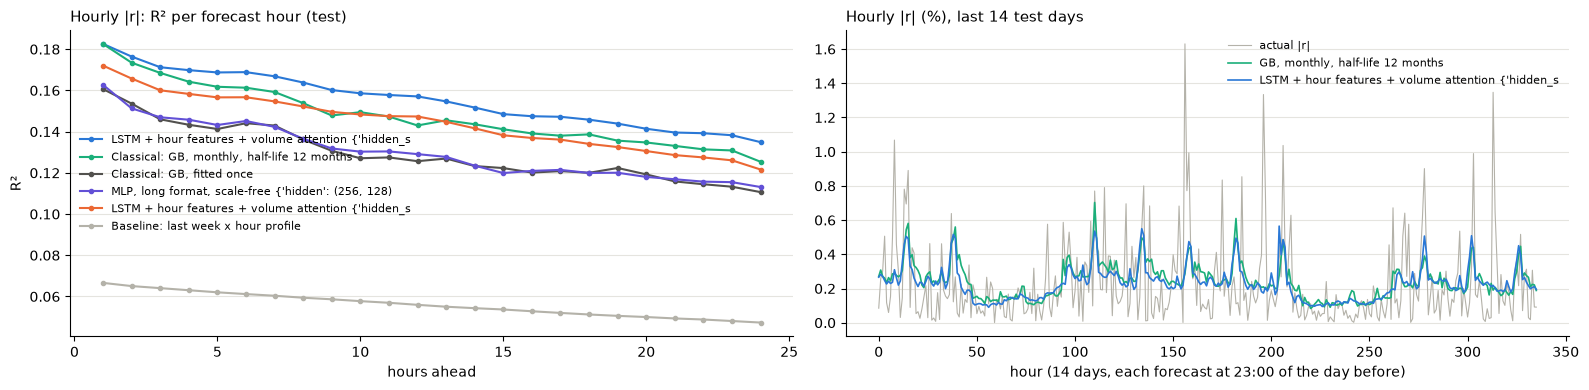

In [21]:
for k, v in abs_seeds.items():
    abs_test[k] = np.mean(v, axis=0)
ENS_REFIT3 = "Ensemble, monthly refits: GB + MLP + LSTM"
ENS_ABS = {"Ensemble: GB + MLP + LSTM": [GB_ABS, MLP_WIN, LSTM_WIN], ENS_REFIT3: [GB_REFIT, MLP_REFIT, LSTM_REFIT]}
for e, members in ENS_ABS.items():
    abs_val[e] = np.mean([abs_val[m] for m in members], axis=0)
    abs_test[e] = np.mean([abs_test[m] for m in members], axis=0)
assert all(abs_val[k].shape == ya["val"].shape and abs_test[k].shape == ya["test"].shape for k in abs_test)


def val_thirds(p):
    # validation R2 on three consecutive half-years, by origin (VAL_PARTS, section 3)
    return {f"val R2 {i + 1}/3": U.r2(ya["val"][rows24(v)], p[rows24(v)]) for i, v in enumerate(VAL_PARTS)}


abs_tab = pd.DataFrame.from_dict({k: {"val R2": U.r2(ya["val"], abs_val[k]), **val_thirds(abs_val[k]), "test R2": U.r2(ya["test"], v),
                                       "test MAE": mean_absolute_error(ya["test"], v), "test corr": safe_corr(v, ya["test"]),
                                       "test R2, single seeds": seed_spread(ya["test"], abs_seeds[k], U.r2) if k in abs_seeds else ""}
                                   for k, v in abs_test.items()}, orient="index")
with pd.option_context("display.max_colwidth", 60):
    display(abs_tab.round(4))
ABS_CHOSEN = abs_tab.drop([k for k in abs_tab.index if k.startswith(("Baseline", "Classical"))])["val R2"].idxmax()
REF_BEST = max([GB_ABS, GB_REFIT], key=lambda k: abs_tab.loc[k, "val R2"])
print(f"chosen on validation (networks and ensembles): {ABS_CHOSEN}")
print(f"best classical reference on validation: {REF_BEST}")
print(f"test R2: {abs_tab.loc[ABS_CHOSEN, 'test R2']:.4f} against {abs_tab.loc[REF_BEST, 'test R2']:.4f} "
      f"({abs_tab.loc[ABS_CHOSEN, 'test R2'] - abs_tab.loc[REF_BEST, 'test R2']:+.4f})")

fig, ax = plt.subplots(1, 2, figsize=(16, 4))
ac = ya["test"].reshape(-1, 24)
for k, c in [(ABS_CHOSEN, BLUE), (GB_REFIT, AQUA), (GB_ABS, INK), (MLP_WIN, PURPLE), (LSTM_WIN, ORANGE),
             ("Baseline: last week x hour profile", GREY)]:
    pr = abs_test[k].reshape(-1, 24)
    ax[0].plot(range(1, 25), [U.r2(ac[:, j], pr[:, j]) for j in range(24)], "o-", ms=3, color=c, label=k[:50])
ax[0].set_xlabel("hours ahead")
ax[0].set_ylabel("R²")
ax[0].legend(frameon=False, fontsize=8)
tidy(ax[0], "Hourly |r|: R² per forecast hour (test)")
seg = test_days[-14:]                                                # last 14 days, one origin per day
ax[1].plot(np.abs(Yte[seg]).reshape(-1), lw=0.8, color=GREY, label="actual |r|")
ax[1].plot(abs_test[GB_REFIT].reshape(-1, 24)[seg].reshape(-1), lw=1.2, color=AQUA, label=GB_REFIT[11:])
ax[1].plot(abs_test[ABS_CHOSEN].reshape(-1, 24)[seg].reshape(-1), lw=1.2, color=BLUE, label=ABS_CHOSEN[:50])
ax[1].set_xlabel("hour (14 days, each forecast at 23:00 of the day before)")
ax[1].legend(frameon=False, fontsize=8)
tidy(ax[1], "Hourly |r| (%), last 14 test days")
plt.tight_layout()
plt.show()

SUMMARY.append({"question": "size of each of the next 24 hours (|r|)", "network (chosen without the test)": f"{ABS_CHOSEN} (best validation R2)",
                "test result": f"R2 {abs_tab.loc[ABS_CHOSEN, 'test R2']:.3f} (MLP {abs_tab.loc[MLP_WIN, 'test R2']:.3f}, "
                               f"MLP refit {abs_tab.loc[MLP_REFIT, 'test R2']:.3f}, LSTM {abs_tab.loc[LSTM_WIN, 'test R2']:.3f}, "
                               f"LSTM fine-tuned {abs_tab.loc[LSTM_REFIT, 'test R2']:.3f})",
                "classical reference (refitted here)": f"GB refitted monthly: R2 {abs_tab.loc[GB_REFIT, 'test R2']:.3f}; "
                                                       f"fitted once {abs_tab.loc[GB_ABS, 'test R2']:.3f}"})

**Release hours.** CPI, payrolls, FOMC and the two hours after FOMC are 0.5% of the rows, invisible in the overall R². Gradient Boosting under-predicts them (leaves of 1,000 rows, against 544 release rows in train); the LSTMs with hour features read B5 directly. The table gives the R² on the release rows and mean(forecast) / mean(actual) on them and on the other hours (below 1: under-predicted).

In [22]:
rel_va, rel_te = release_rows("val"), release_rows("test")
print(f"rows whose predicted hour is a release hour: validation {rel_va.sum():,} ({rel_va.mean():.2%}), "
      f"test {rel_te.sum():,} ({rel_te.mean():.2%})")


def release_scores(y, p, rel):
    return {"R2, release hours": U.r2(y[rel], p[rel]), "pred / actual, release hours": p[rel].mean() / y[rel].mean(),
            "pred / actual, other hours": p[~rel].mean() / y[~rel].mean()}


rel_models = ["Baseline: last week x hour profile"] + [k for k in abs_tab.index if not k.startswith("Baseline")]
rel_tab = pd.DataFrame({k: {**{f"val {c}": v for c, v in release_scores(ya["val"], abs_val[k], rel_va).items()},
                            **{f"test {c}": v for c, v in release_scores(ya["test"], abs_test[k], rel_te).items()}}
                        for k in rel_models}).T
with pd.option_context("display.max_colwidth", 60):
    display(rel_tab.round(3))

rows whose predicted hour is a release hour: validation 288 (0.56%), test 2,568 (0.54%)


,"val R2, release hours","val pred / actual, release hours","val pred / actual, other hours","test R2, release hours","test pred / actual, release hours","test pred / actual, other hours"
Baseline: last week x hour profile,-0.316,0.332,1.010,-0.238,0.569,1.005
"Classical: GB, fitted once",-0.269,0.391,1.046,-0.132,0.648,1.007
"Classical: GB, monthly, half-life 12 months",-0.226,0.421,1.034,-0.099,0.660,1.021
"MLP, long format {'hidden': (256, 128), 'weight_decay': 0.01}",-0.237,0.397,1.010,-0.134,0.654,0.977
"MLP, long format, scale-free {'hidden': (256, 128), 'weight_decay': 0.01}",-0.222,0.411,1.044,-0.110,0.694,1.028
LSTM {'hidden_size': 128},-0.261,0.393,1.048,-0.115,0.683,1.025
LSTM + hour features {'hidden_size': 64},-0.102,0.926,1.056,-0.483,1.596,1.043
"LSTM + hour features, scale-free {'hidden_size': 64}",-0.000,0.779,1.083,-0.406,1.410,1.028
LSTM + hour features + volume attention {'hidden_size': 64},-0.073,0.946,1.045,-0.416,1.556,1.024
"MLP, long format, scale-free {'hidden': (256, 128), 'weight_decay': 0.01}, every origin",-0.224,0.406,1.036,-0.091,0.700,1.032


### 5.6 What we see

**Answer: yes, narrowly. The network chosen on validation, the LSTM with hour features and volume attention fine-tuned every month, has test R² 0.156, reliably above the refitted Gradient Boosting (0.148): +0.008, interval [+0.001, +0.015], better in 98.7% of the resamples.**

| Model | val R² | test R² |
|---|---|---|
| Gradient Boosting, fitted once / refitted monthly | 0.0947 / 0.1005 | 0.1295 / 0.1479 |
| MLP / scale-free (`MLP_WIN`) / scale-free on every origin / scale-free refitted monthly | 0.0945 / 0.0958 / 0.0994 / 0.1015 | 0.1328 / 0.1303 / 0.1406 / 0.1428 |
| LSTM / + hour features / + hour features, scale-free / + hour features + volume attention | 0.0999 / 0.1161 / 0.1127 / 0.1200 | 0.0997 / 0.1308 / 0.1400 / 0.1445 |
| **LSTM + volume attention, fine-tuned monthly** (chosen) | **0.1208** | **0.1556** |
| Ensemble fitted once / monthly refits | 0.1153 / 0.1197 | 0.1473 / **0.1611** |

- **Inputs and Gradient Boosting:** `CHOSEN_SET` = base + B3, as in `classical-models.ipynb`; the monthly refit adds +0.018 (interval [+0.012, +0.025]).
- **The MLP ties the trees** on the same rows: +0.003 over Gradient Boosting fitted once, −0.005 refitted monthly (both intervals include 0). Every origin and the monthly refit each help `MLP_WIN` (+0.010 and +0.013 on test).
- **The LSTM needs to know which hours it predicts:** the hour features add +0.031 (interval [+0.024, +0.039]), the largest gain of a network here.
- **Volume attention helps:** +0.014 over the LSTM + hour features (interval [+0.009, +0.019]) and the best validation R² of the LSTMs. The networks learn β ≈ 0.92 and put 38% of the weight on the 10% most traded hours of the week: they use the mask.
- **Scale-free target:** reliably better for the LSTM on test (+0.009, [+0.004, +0.016]) but worse on validation, so it was not chosen; no help for the MLP (−0.003, a tie), although validation preferred it.
- **The ensemble of the three monthly refits is the best on test** (0.161, +0.013 over the refitted Gradient Boosting, [+0.009, +0.018]), but its validation R² is 0.001 below the chosen LSTM's. The choice rests on two of the three validation half-years: in the second, Gradient Boosting refitted monthly and the ensembles lead.
- **The fair validation works:** with early stopping on its own block the validation R² of the networks is no longer inflated (LSTM + hour features 0.123 → 0.116), and the networks now rise from validation to test as Gradient Boosting does.
- **Release hours:** Gradient Boosting under-predicts them (test forecast 0.65× the actual). The LSTMs with hour features come close on validation (0.78–1.06×) but over-predict them on test (1.3–1.6×, R² −0.19 to −0.48). The ensembles land in between (0.90–0.97×) and are the only models with R² ≥ 0 there. The other hours are unaffected.
- **Seeds:** single seeds spread by ±0.001–0.005; averaging 5 seeds adds up to +0.006.

## 6. Next-day volatility

**Question.** How volatile will tomorrow be? Target: the log of the next day's realized volatility, forecast at 23:00 (wide format). **To beat:** Gradient Boosting, walk-forward R² 0.350 and test 0.505 (`classical-models.ipynb` §8.4).

**Inputs:** the base features, B4 and the release flags of the next 24 hours. **Models:** Gradient Boosting (classical grid), an MLP (`MLPRegressor`; size, L2 penalty and 25–800 epochs tuned, no early stopping) and their average. Choice on the **4 walk-forward folds** over train + validation; test on the 829 independent days.

MLP: walk-forward R2 against the number of epochs, for the chosen size and penalty


param_mlpregressor__max_iter,25,50,100,200,400,800
mean_test_score,0.2501,0.2860,0.2581,0.2449,0.2361,0.2361
std_test_score,0.1662,0.1294,0.1495,0.1651,0.1757,0.1757


,test R2,test MAE,test corr,"test R2, single seeds",WF R2,WF std,fold1,fold2,fold3,fold4
Baseline: last week's average volatility,0.0941,0.3851,0.4467,,NaN,NaN,NaN,NaN,NaN,NaN
"Classical: Gradient Boosting, base only {'learning_rate': 0.05, 'max_depth': 2, 'max_iter': 200, 'min_samples_leaf': 100}",0.5113,0.2880,0.7167,,0.3500,0.0746,0.2820,0.2961,0.3814,0.4404
"Classical: Gradient Boosting {'learning_rate': 0.05, 'max_depth': 2, 'max_iter': 200, 'min_samples_leaf': 100}",0.5050,0.2903,0.7138,,0.3503,0.0776,0.2803,0.2932,0.3839,0.4440
"MLP {'alpha': 1.0, 'hidden_layer_sizes': (64, 32), 'max_iter': 50}",0.5046,0.2919,0.7117,0.4966 ± 0.0082,0.2860,0.1494,0.1336,0.1833,0.3945,0.4324
Ensemble: GB + MLP,0.5162,0.2878,0.7220,,0.3557,0.0848,0.2958,0.2736,0.4027,0.4506


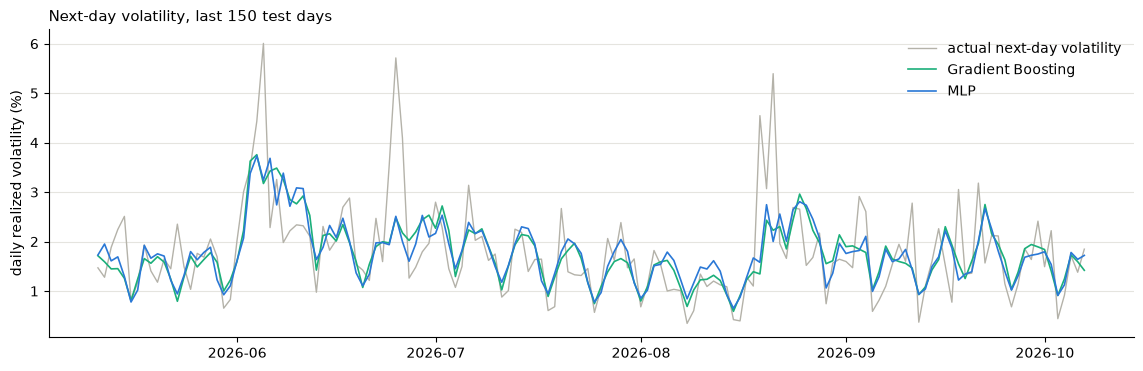

In [23]:
DV_COLS = BASE + B4 + NEXT_DAY_FEATURES                              # base + B4 + release in the next 24 hours
XW_tv, XW_te = Xw("tv", DV_COLS), Xw("test", DV_COLS)[test_days]
yd_tv, yd_te = U.day_log_vol(Ytv), U.day_log_vol(Yte[test_days])
lr_h = np.log1p(ret / U.PCT) * U.PCT                                 # hourly log returns, %
p_days = P["test"][test_days]
NAIVE_DV = "Baseline: last week's average volatility"
dv_test = {NAIVE_DV: np.log(np.sqrt(np.array([(lr_h[p - 167: p + 1] ** 2).sum() / 7 for p in p_days])) + 1e-6)}


def wf_folds(gs):
    # walk-forward scores of the chosen setting: mean, std and each fold
    f = [gs.cv_results_[f"split{i}_test_score"][gs.best_index_] for i in range(len(WF))]
    return {"WF R2": np.mean(f), "WF std": np.std(f, ddof=1), **{f"fold{i + 1}": s for i, s in enumerate(f)}}


GB_DV_GRID = {"learning_rate": [0.05, 0.1], "max_depth": [2, 3], "min_samples_leaf": [20, 100], "max_iter": [50, 100, 200]}
gb_dv_base = GridSearchCV(HistGradientBoostingRegressor(early_stopping=False, random_state=RANDOM_STATE),
                          GB_DV_GRID, cv=WF, scoring="r2", n_jobs=N_JOBS).fit(Ftv, yd_tv)
gb_dv = GridSearchCV(HistGradientBoostingRegressor(early_stopping=False, random_state=RANDOM_STATE),
                     GB_DV_GRID, cv=WF, scoring="r2", n_jobs=N_JOBS).fit(XW_tv, yd_tv)
MLP_DV_GRID = {"mlpregressor__hidden_layer_sizes": [(16,), (64, 32)], "mlpregressor__alpha": [0.1, 1.0, 10.0, 100.0],
               "mlpregressor__max_iter": [25, 50, 100, 200, 400, 800]}
mlp_dv = GridSearchCV(make_pipeline(StandardScaler(), MLPRegressor(early_stopping=False, random_state=RANDOM_STATE)),
                      MLP_DV_GRID, cv=WF, scoring="r2", n_jobs=N_JOBS).fit(XW_tv, yd_tv)
GB_DV_BASE = f"Classical: Gradient Boosting, base only {gb_dv_base.best_params_}"
GB_DV = f"Classical: Gradient Boosting {gb_dv.best_params_}"
MLP_DV = f"MLP {({k.split('__')[1]: v for k, v in mlp_dv.best_params_.items()})}"
print("MLP: walk-forward R2 against the number of epochs, for the chosen size and penalty")
cv = pd.DataFrame(mlp_dv.cv_results_)
same = np.all([cv[f"param_{k}"].map(str) == str(v) for k, v in mlp_dv.best_params_.items() if not k.endswith("max_iter")], axis=0)
display(cv[same].set_index("param_mlpregressor__max_iter")[["mean_test_score", "std_test_score"]].T.round(4))

dv_wf = {GB_DV_BASE: wf_folds(gb_dv_base), GB_DV: wf_folds(gb_dv), MLP_DV: wf_folds(mlp_dv)}
fold_pred = {k: [clone(gs.best_estimator_).fit(XW_tv[a], yd_tv[a]).predict(XW_tv[b]) for a, b in WF] for k, gs in [(GB_DV, gb_dv), (MLP_DV, mlp_dv)]}
ENS_DV = "Ensemble: GB + MLP"
f = [U.r2(yd_tv[b], (fold_pred[GB_DV][i] + fold_pred[MLP_DV][i]) / 2) for i, (_, b) in enumerate(WF)]
dv_wf[ENS_DV] = {"WF R2": np.mean(f), "WF std": np.std(f, ddof=1), **{f"fold{i + 1}": s for i, s in enumerate(f)}}

dv_seeds = {MLP_DV: [clone(mlp_dv.best_estimator_).set_params(mlpregressor__random_state=RANDOM_STATE + s).fit(XW_tv, yd_tv).predict(XW_te)
                     for s in range(N_SEEDS)]}
dv_test.update({GB_DV_BASE: gb_dv_base.predict(Fte[test_days]), GB_DV: gb_dv.predict(XW_te), MLP_DV: np.mean(dv_seeds[MLP_DV], axis=0)})
dv_test[ENS_DV] = (dv_test[GB_DV] + dv_test[MLP_DV]) / 2
dv_tab = pd.DataFrame.from_dict({k: {**dv_wf.get(k, {}), "test R2": U.r2(yd_te, v), "test MAE": mean_absolute_error(yd_te, v),
                                      "test corr": safe_corr(v, yd_te),
                                      "test R2, single seeds": seed_spread(yd_te, dv_seeds[k], U.r2) if k in dv_seeds else ""}
                                  for k, v in dv_test.items()}, orient="index")
display(dv_tab.round(4))
DV_CHOSEN = max([MLP_DV, ENS_DV], key=lambda k: dv_wf[k]["WF R2"])

fig, ax = plt.subplots(figsize=(14, 4))
last = slice(-150, None)
ax.plot(D["test"][test_days][last], np.exp(yd_te[last]), color=GREY, lw=1, label="actual next-day volatility")
ax.plot(D["test"][test_days][last], np.exp(dv_test[GB_DV][last]), color=AQUA, lw=1.2, label="Gradient Boosting")
ax.plot(D["test"][test_days][last], np.exp(dv_test[MLP_DV][last]), color=BLUE, lw=1.2, label="MLP")
ax.set_ylabel("daily realized volatility (%)")
ax.legend(frameon=False)
tidy(ax, "Next-day volatility, last 150 test days")
plt.show()

SUMMARY.append({"question": "next-day volatility", "network (chosen without the test)": f"{DV_CHOSEN} (best walk-forward R2 of MLP / ensemble)",
                "test result": f"R2 {U.r2(yd_te, dv_test[DV_CHOSEN]):.3f} (MLP alone {U.r2(yd_te, dv_test[MLP_DV]):.3f})",
                "classical reference (refitted here)": f"GB: R2 {U.r2(yd_te, dv_test[GB_DV]):.3f} (base only {U.r2(yd_te, dv_test[GB_DV_BASE]):.3f}); "
                                                       f"last week's average {U.r2(yd_te, dv_test[NAIVE_DV]):.3f}"})

### 6.1 What we see

**Answer: the MLP alone ties Gradient Boosting; averaged with it, it is reliably better: R² 0.516 against 0.505.**

- **The ensemble GB + MLP** has the best walk-forward R² (0.356 against 0.350, better on 3 of 4 folds) and is chosen. Test: +0.011 over Gradient Boosting, interval [+0.001, +0.022], better in 97.9% of the resamples.
- **The MLP** (64, 32), alpha 1, 50 epochs: below Gradient Boosting on the folds (0.286, twice the spread) but equal on test (0.505; −0.000, [−0.023, +0.021]). More epochs are worse (0.236 at 400–800).
- **The new inputs change nothing:** Gradient Boosting has the same walk-forward R² with or without B4 and the releases (test 0.505 with, 0.511 without).

## 7. How sure are we? Bootstrap confidence intervals

Moving-block bootstrap as in `classical-models.ipynb` §11: the 829 test days are resampled in blocks of 10 days, 1,000 times, each day bringing its 24 test origins. A **difference** between two models on the same resampled days is reliable if its 95% interval excludes 0.

In [24]:
def day_orig(idx):
    # all test origins of the chosen independent days (the last day may be incomplete)
    o = (test_days[idx][:, None] + np.arange(24)).ravel()
    return o[o < len(P["test"])]


days_rows = lambda idx: rows24(day_orig(idx))                        # their 24 long-format rows each
r2_days = lambda pred, i: U.r2(ya["test"][days_rows(i)], pred[days_rows(i)])
auc_days = lambda score, i: roc_auc_score(y1["test"][day_orig(i)] > 0, score[day_orig(i)])
ret_chosen = test_preds[RET_CHOSEN]
boot_stats = {
    f"24 hourly returns R²_oos, {RET_CHOSEN}": lambda i: U.r2_oos(Yte[day_orig(i)], ret_chosen[day_orig(i)]),
    f"24 hourly returns IC, {RET_CHOSEN}": lambda i: safe_corr(ret_chosen[day_orig(i)], Yte[day_orig(i)]),
    f"next-hour AUC, {DIR_CHOSEN.split(' {')[0]} − GB": lambda i: auc_days(dir_scores[DIR_CHOSEN], i) - auc_days(dir_scores[GB_DIR], i),
    f"hourly |r| R², {ABS_CHOSEN}": lambda i: r2_days(abs_test[ABS_CHOSEN], i),
    f"hourly |r| R², {ABS_CHOSEN} − GB fitted once": lambda i: r2_days(abs_test[ABS_CHOSEN], i) - r2_days(abs_test[GB_ABS], i),
    f"hourly |r| R², {ABS_CHOSEN} − GB refitted monthly": lambda i: r2_days(abs_test[ABS_CHOSEN], i) - r2_days(abs_test[GB_REFIT], i),
    "hourly |r| R², GB refitted monthly − GB fitted once": lambda i: r2_days(abs_test[GB_REFIT], i) - r2_days(abs_test[GB_ABS], i),
    "hourly |r| R², MLP − GB fitted once": lambda i: r2_days(abs_test[MLP_ABS], i) - r2_days(abs_test[GB_ABS], i),
    "hourly |r| R², MLP refitted monthly − GB refitted monthly": lambda i: r2_days(abs_test[MLP_REFIT], i) - r2_days(abs_test[GB_REFIT], i),
    f"hourly |r| R², {LSTM_WIN.split(' {')[0]} − GB fitted once": lambda i: r2_days(abs_test[LSTM_WIN], i) - r2_days(abs_test[GB_ABS], i),
    "hourly |r| R², LSTM + hour features − LSTM": lambda i: r2_days(abs_test[LSTM_FUT], i) - r2_days(abs_test[LSTM_ABS], i),
    "hourly |r| R², LSTM fine-tuned monthly − GB refitted monthly": lambda i: r2_days(abs_test[LSTM_REFIT], i) - r2_days(abs_test[GB_REFIT], i),
    "hourly |r| R², LSTM fine-tuned monthly − the same LSTM fitted once": lambda i: r2_days(abs_test[LSTM_REFIT], i) - r2_days(abs_test[LSTM_WIN], i),
    "hourly |r| R², ensemble of the 3 monthly refits − GB refitted monthly": lambda i: r2_days(abs_test[ENS_REFIT3], i) - r2_days(abs_test[GB_REFIT], i),
    "hourly |r| R², MLP scale-free − MLP": lambda i: r2_days(abs_test[MLP_SF], i) - r2_days(abs_test[MLP_ABS], i),
    "hourly |r| R², LSTM + hour features scale-free − LSTM + hour features": lambda i: r2_days(abs_test[LSTM_SF], i) - r2_days(abs_test[LSTM_FUT], i),
    "hourly |r| R², LSTM + volume attention − LSTM + hour features": lambda i: r2_days(abs_test[LSTM_ATT], i) - r2_days(abs_test[LSTM_FUT], i),
    "next-day vol R², MLP − GB": lambda i: U.r2(yd_te[i], dv_test[MLP_DV][i]) - U.r2(yd_te[i], dv_test[GB_DV][i]),
    "next-day vol R², ensemble GB + MLP − GB": lambda i: U.r2(yd_te[i], dv_test[ENS_DV][i]) - U.r2(yd_te[i], dv_test[GB_DV][i]),
}
boot_rows = {}
for name, fn in boot_stats.items():
    b = U.block_bootstrap(fn, ND, n_boot=1000, block=10, seed=RANDOM_STATE)
    boot_rows[name] = {"estimate": fn(np.arange(ND)), "CI 2.5%": np.percentile(b, 2.5), "CI 97.5%": np.percentile(b, 97.5),
                       "share of resamples > 0": (b > 0).mean()}
with pd.option_context("display.max_colwidth", 90):
    display(pd.DataFrame(boot_rows).T.round(4))

,estimate,CI 2.5%,CI 97.5%,share of resamples > 0
"24 hourly returns R²_oos, LSTM, Huber loss",-0.0005,-0.0011,0.0001,0.054
"24 hourly returns IC, LSTM, Huber loss",0.0044,-0.0002,0.0085,0.970
"next-hour AUC, LSTM classifier, every origin (25 epochs) − GB",0.0050,-0.0017,0.0119,0.925
"hourly |r| R², LSTM + hour features + volume attention {'hidden_size': 64}, fine-tuned monthly",0.1556,0.1325,0.1801,1.000
"hourly |r| R², LSTM + hour features + volume attention {'hidden_size': 64}, fine-tuned monthly − GB fitted once",0.0261,0.0183,0.0342,1.000
"hourly |r| R², LSTM + hour features + volume attention {'hidden_size': 64}, fine-tuned monthly − GB refitted monthly",0.0077,0.0009,0.0151,0.987
"hourly |r| R², GB refitted monthly − GB fitted once",0.0184,0.0119,0.0254,1.000
"hourly |r| R², MLP − GB fitted once",0.0033,-0.0034,0.0107,0.828
"hourly |r| R², MLP refitted monthly − GB refitted monthly",-0.0051,-0.0109,0.0013,0.050
"hourly |r| R², LSTM + hour features + volume attention − GB fitted once",0.0150,0.0063,0.0236,1.000


### 7.1 What the intervals say

| Question | Difference | Reliable? |
|---|---|---|
| 24 hourly returns | LSTM, Huber: R²_oos −0.0005 [−0.0011, +0.0001], IC +0.004 [−0.000, +0.009] | no: the zero forecast is not beaten |
| Next-hour direction | LSTM every origin − GB: AUC +0.005 [−0.002, +0.012] | no: a tie |
| Size of each hourly move | **chosen LSTM − GB refitted monthly: +0.008 [+0.001, +0.015]** | **yes**, network better |
| | chosen LSTM − GB fitted once: +0.026 [+0.018, +0.034] | yes |
| | GB refitted monthly − GB fitted once: +0.018 [+0.012, +0.025] | yes |
| | LSTM fine-tuned − the same LSTM fitted once: +0.011 [+0.007, +0.016] | yes |
| | LSTM + volume attention − LSTM + hour features: +0.014 [+0.009, +0.019] | yes |
| | LSTM + hour features − LSTM: +0.031 [+0.024, +0.039] | yes |
| | LSTM scale-free − LSTM + hour features: +0.009 [+0.004, +0.016] | yes (not chosen on validation) |
| | ensemble of monthly refits − GB refitted monthly: +0.013 [+0.009, +0.018] | yes (not chosen on validation) |
| | MLP − GB fitted once: +0.003 [−0.003, +0.011]; MLP refitted − GB refitted: −0.005 [−0.011, +0.001]; MLP scale-free − MLP: −0.003 [−0.007, +0.002] | no: ties |
| Next-day volatility | ensemble GB + MLP − GB: **+0.011 [+0.001, +0.022]** | **yes** |
| | MLP − GB: −0.000 [−0.023, +0.021] | no: a tie |

Two models chosen without the test are reliably better than their classical reference: the \|r\| LSTM and the volatility ensemble. Both margins are small, and the lower ends of their intervals are close to 0.

## 8. Conclusions

### 8.1 This run

The main test result of each section, next to the classical reference refitted here:

In [25]:
with pd.option_context("display.max_colwidth", 120):
    display(pd.DataFrame(SUMMARY).set_index("question"))
print(f"Total run time: {(time.time() - T_START) / 60:.1f} minutes")

,network (chosen without the test),test result,classical reference (refitted here)
question,,,
24 hourly returns,"LSTM, Huber loss (of MLP, LSTM with MSE / Huber)","MAE skill -0.0006 (all networks -0.0006 to -0.0004), IC +0.004",Ridge: MAE skill -0.0003
direction of the next hour,"LSTM classifier, every origin (25 epochs) (best validation AUC)","AUC 0.538, top 10% right 59.9% (p = 4e-19)",GB AUC 0.533; reversal rule 0.528
size of each of the next 24 hours (|r|),"LSTM + hour features + volume attention {'hidden_size': 64}, fine-tuned monthly (best validation R2)","R2 0.156 (MLP 0.130, MLP refit 0.143, LSTM 0.144, LSTM fine-tuned 0.156)",GB refitted monthly: R2 0.148; fitted once 0.130
next-day volatility,Ensemble: GB + MLP (best walk-forward R2 of MLP / ensemble),R2 0.516 (MLP alone 0.505),GB: R2 0.505 (base only 0.511); last week's average 0.094


Total run time: 33.0 minutes


### 8.2 Conclusions

1. **Hourly returns stay at the zero forecast** (section 3). Window-normalized inputs and the Huber loss, the README's fixes for `model_test.ipynb`, change nothing: the target has no signal for any model.
2. **Next-hour direction: a tie** (section 4). The LSTM reaches Gradient Boosting (AUC 0.538 against 0.533) only when trained on every origin, which helps the trees as much (0.541).
3. **Size of the hourly moves: a network beats the best classical model** (section 5). Three ingredients, each reliable on test: telling the LSTM which hours it predicts (+0.031), reading the week through a volume attention mask (+0.014) and fine-tuning it every month (+0.011). Together they reach R² 0.156, +0.008 over Gradient Boosting refitted monthly. The MLP only ties the trees. Averaging the three families refitted monthly is better still on test (0.161), but validation could not separate it from the LSTM.
4. **Next-day volatility: the network helps as a second model** (section 6). The ensemble GB + MLP is reliably better than Gradient Boosting (0.516 against 0.505); the MLP alone ties.
5. **What the networks still miss:** the release hours. The LSTMs read the release flags and over-correct on test (1.3–1.6× the actual size, where Gradient Boosting gives 0.65×). Averaging with the trees fixes most of it.
6. **The picture of `classical-models.ipynb` mostly holds**: the large gains come from asking the questions the data can answer, the long format and monthly refits, which help the networks as much as the trees. The networks add a small, reliable gain where there is signal at the hourly level, at a cost of 33 minutes on a GPU.

### 8.3 The archived conclusions, checked against this run

- *(README)* "Hourly Bitcoin returns are close to a random walk: no model beats predicting 0% change." → **Still holds.**
- *(versions 1–2)* "Weak regularization overfits badly; from alpha = 100–1000 the result does not change." → **Still holds** (validation down to −0.050 at alpha 0.01).
- *(README, on `model_test.ipynb`)* The networks may be held back by global-scaled prices and the MSE loss. → **No:** after both fixes the LSTM still equals the zero forecast; the target holds it back.
- *(README, task 7)* Rerun the LSTM on the volatility / hourly-size targets with monthly refits. → Done: on the hourly size the LSTM finds real signal and, fine-tuned every month, beats the refitted tree model.

### 8.4 Not done here

- **Walk-forward folds for the networks:** each choice rests on one 18-month validation block, and in section 5 the chosen LSTM and the best ensemble differ by 0.001 there.
- **Volume attention and the scale-free input together**, and both in the networks of sections 3–4; a learned attention to compare with the volume mask.
- **Release hours:** a loss or a shrinkage that stops the LSTM from over-predicting them.
- Monthly refits and an LSTM for next-day volatility; quantile networks for the 80% ranges; GRU, temporal convolutions, Transformers; the Binance attributes.